# EN4554 — Assignment 2: Convolutional Neural Networks

**Name:** De Zoysa A. S. I.

**Index No.:** 220106D

**GitHub repository:** https://github.com/Sithum02/EN4554_A02 (the original notebook file can be found here)

**Use of AI tools.** I used Claude (Anthropic) as a coding assistant while writing this notebook. I have read, run and understood all of the code, and the interpretations reflect my own understanding of the results.

### Contents
0. Setup: data split, normalisation, seeds and shared training utilities
1. Task 1: Backpropagation from scratch (Linear, ReLU, softmax cross-entropy), gradient checking, MLP training, vanishing gradients
2. Task 2: Optimizers (SGD with momentum and Adam as `torch.optim.Optimizer` subclasses), trajectories on an ill-conditioned quadratic, learning-rate sensitivity
3. Task 3: Regularization on a 5k training subset; plain vs residual networks of depth 8 / 20 / 56
4. Task 4: Best CNN with at most 500k parameters and at most 20 epochs, with an ablation study and a single test-set evaluation
5. Summary

**Protocol used throughout.** The CIFAR-10 training set (50k) is split once, with a fixed seed, into **45k train / 5k validation**. Each channel is normalised with the mean and standard deviation of the **45k training split only**. All model selection uses the validation split. The **test set is loaded and used exactly once, at the end of Task 4.** Seeds are fixed for every run.

**Running the notebook.** It is written for a Colab T4 GPU (Runtime → Change runtime type → T4 GPU). Because the official CIFAR-10 server is often very slow, the data are downloaded from the Hugging Face mirror and verified against a checksum of the official dataset. The whole dataset sits in GPU memory and augmentations run on the GPU, which avoids the slow CPU data-loading of Colab. Every finished training run is cached as JSON (on Google Drive when on Colab), so after a disconnect, *Run all* skips the runs that have already finished.

## 0. Setup

In [1]:
import os, sys, json, math, time, copy, random, warnings
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

warnings.filterwarnings('ignore', message='Detected call of')   # harmless: AMP may skip the very first optimizer step

IN_COLAB = 'google.colab' in sys.modules
QUICK = os.environ.get('A2_QUICK', '0') == '1'  # tiny smoke-test runs only; False for the real report
USE_DRIVE = True       # on Colab, cache results on Google Drive so a disconnect does not lose finished runs
FORCE_RERUN = False    # True -> ignore cached results and retrain everything

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'          # mixed precision (fp16) for the CNN experiments on the GPU
torch.backends.cudnn.benchmark = True    # fastest conv kernels (seeds are fixed; GPU kernels are not bit-exact)

if IN_COLAB and USE_DRIVE and not QUICK:
    from google.colab import drive
    drive.mount('/content/drive')
    RESULTS_DIR = '/content/drive/MyDrive/EN4554_A2_results'
else:
    RESULTS_DIR = 'results_quick' if QUICK else 'results'
os.makedirs(RESULTS_DIR, exist_ok=True)
DATA_DIR = './data'

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

def E(n_epochs):
    """Number of epochs to train for (1 in QUICK smoke-test mode)."""
    return 1 if QUICK else n_epochs

pd.set_option('display.max_colwidth', None)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
gpu = f' ({torch.cuda.get_device_name(0)})' if device.type == 'cuda' else ''
print(f'torch {torch.__version__} | device: {device}{gpu} | AMP: {USE_AMP} | QUICK: {QUICK} | results -> {RESULTS_DIR}')

Mounted at /content/drive
torch 2.11.0+cu130 | device: cuda (Tesla T4) | AMP: True | QUICK: False | results -> /content/drive/MyDrive/EN4554_A2_results


In [2]:
def cached(name, fn, extra_files=()):
    """Run fn() once and store its JSON-serialisable dict in RESULTS_DIR; later calls load it from disk.
    A run is redone only if its JSON (or one of its extra_files, e.g. saved weights) is missing."""
    path = os.path.join(RESULTS_DIR, name + '.json')
    done = os.path.exists(path) and all(os.path.exists(os.path.join(RESULTS_DIR, f)) for f in extra_files)
    if done and not FORCE_RERUN:
        with open(path) as f:
            return json.load(f)
    t0 = time.time()
    res = fn()
    res['wall_time_s'] = time.time() - t0
    with open(path, 'w') as f:
        json.dump(res, f)
    return res

### 0.1 Data: 45k / 5k split and per-channel normalisation

100%|██████████| 114M/114M [00:01<00:00, 93.0MB/s]


CIFAR-10 training set loaded and verified against the official checksum
train: (45000, 3, 32, 32) | val: (5000, 3, 32, 32)
channel mean (train split): [0.4917 0.4823 0.4467] | channel std: [0.2471 0.2435 0.2616]
normalised train mean per channel: [-0.  0. -0.] | std: [1. 1. 1.]


,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
train,4512,4488,4468,4529,4529,4486,4493,4500,4496,4499
val,488,512,532,471,471,514,507,500,504,501


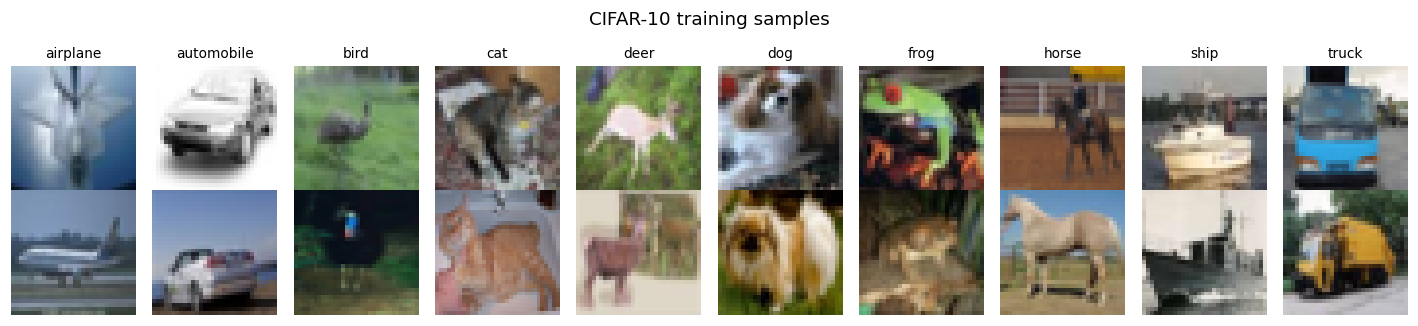

In [3]:
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
HF_URL = 'https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/{}-00000-of-00001.parquet'
CIFAR_MD5 = {'train': '11490a97f37274deadbd59c1c60b3fc6', 'test': '23ab8122b1552d6947b8138cb712b939'}

def load_cifar10(split):
    """CIFAR-10 as (uint8 images (N, 32, 32, 3), int64 labels), in the official order.
    The official server (cs.toronto.edu) is often extremely slow, so if the official archive is not already on disk
    the identical data is downloaded from the Hugging Face mirror. The mirror stores the 5 training batches in a
    different order, so they are put back in the official order and the result is verified against an MD5 checksum
    of the official arrays (so the train/val split is exactly the same whichever source is used)."""
    import hashlib, io
    from PIL import Image
    if os.path.isdir(os.path.join(DATA_DIR, 'cifar-10-batches-py')):
        ds = torchvision.datasets.CIFAR10(DATA_DIR, train=(split == 'train'), download=False)
        data, labels = ds.data, np.array(ds.targets, dtype=np.int64)
    else:
        os.makedirs(DATA_DIR, exist_ok=True)
        path = os.path.join(DATA_DIR, f'cifar10_{split}.parquet')
        if not os.path.exists(path):
            torch.hub.download_url_to_file(HF_URL.format(split), path)
        df = pd.read_parquet(path)
        data = np.stack([np.array(Image.open(io.BytesIO(d['bytes'])).convert('RGB')) for d in df['img']])
        labels = df['label'].to_numpy().astype(np.int64)
        if split == 'train':   # mirror rows [40k:50k, 20k:30k, 10k:20k, 0:10k, 30k:40k] = official batches 1..5
            order = np.concatenate([np.arange(s, s + 10000) for s in (40000, 20000, 10000, 0, 30000)])
            data, labels = data[order], labels[order]
    md5 = hashlib.md5(np.ascontiguousarray(data).tobytes() + labels.tobytes()).hexdigest()
    assert md5 == CIFAR_MD5[split], f'CIFAR-10 {split} data does not match the official dataset (md5 {md5})'
    return data, labels

train_data, train_labels = load_cifar10('train')
X_all = torch.from_numpy(train_data).permute(0, 3, 1, 2).float().div_(255)  # (50000, 3, 32, 32) in [0, 1]
y_all = torch.from_numpy(train_labels)
print('CIFAR-10 training set loaded and verified against the official checksum')

perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45000], perm[45000:]

# per-channel statistics from the 45k TRAINING split only (no information from validation/test leaks in)
MEAN = X_all[train_idx].mean(dim=(0, 2, 3))
STD = X_all[train_idx].std(dim=(0, 2, 3))

def normalize(x):
    return (x - MEAN.view(1, 3, 1, 1)) / STD.view(1, 3, 1, 1)

def denormalize(x):
    return (x.cpu() * STD.view(1, 3, 1, 1) + MEAN.view(1, 3, 1, 1)).clamp(0, 1)

if QUICK:  # smoke test only: small subsets
    train_idx, val_idx = train_idx[:6000], val_idx[:1000]

X_train, y_train = normalize(X_all[train_idx]).to(device), y_all[train_idx].to(device)
X_val, y_val = normalize(X_all[val_idx]).to(device), y_all[val_idx].to(device)
del X_all

print('train:', tuple(X_train.shape), '| val:', tuple(X_val.shape))
print('channel mean (train split):', MEAN.numpy().round(4), '| channel std:', STD.numpy().round(4))
print('normalised train mean per channel:', X_train.mean(dim=(0, 2, 3)).cpu().numpy().round(4),
      '| std:', X_train.std(dim=(0, 2, 3)).cpu().numpy().round(4))
counts = pd.DataFrame({'train': np.bincount(y_train.cpu(), minlength=10),
                       'val': np.bincount(y_val.cpu(), minlength=10)}, index=CLASSES).T
display(counts)

fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for c in range(10):
    idx = (y_train == c).nonzero().squeeze(1)[:2]
    for r in range(2):
        axes[r, c].imshow(denormalize(X_train[idx[r]][None])[0].permute(1, 2, 0))
        axes[r, c].axis('off')
    axes[0, c].set_title(CLASSES[c], fontsize=9)
plt.suptitle('CIFAR-10 training samples')
plt.tight_layout()
plt.show()

The split is random rather than stratified, but the counts above show that both halves are close to balanced: 4,468–4,529 training and 471–532 validation images per class. The training-split statistics (mean ≈ (0.49, 0.48, 0.45), std ≈ (0.25, 0.24, 0.26)) are the usual CIFAR-10 values. After normalisation every training channel has mean 0 and standard deviation 1. The validation images use the *same* training statistics, so the validation split leaks nothing into the preprocessing.

### 0.2 Shared utilities: GPU mini-batching, augmentations, training loop

All of CIFAR-10 (≈0.6 GB as float32) is stored on the GPU. Each mini-batch is an index into that tensor, and every augmentation is a vectorised tensor operation on the whole batch. This is much faster than a CPU `DataLoader` on Colab's two CPU cores. Cutout and mixup are implemented here by hand, as the assignment requires.

In [4]:
def batches(X, y, batch_size, shuffle=True, drop_last=False):
    """Yield mini-batches (X[b], y[b]) from GPU-resident tensors."""
    n = len(X)
    idx = torch.randperm(n, device=X.device) if shuffle else torch.arange(n, device=X.device)
    stop = n - n % batch_size if drop_last else n
    for i in range(0, stop, batch_size):
        b = idx[i:i + batch_size]
        yield X[b], y[b]

# ---------------- augmentations (operate on a whole normalised batch on the GPU) ----------------
def random_flip(x):
    """Horizontal flip of each image with probability 1/2."""
    flip = torch.rand(x.size(0), device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)

def random_crop(x, pad=4):
    """Zero-pad by `pad` pixels and take a random 32x32 crop per image (zero = mean colour after normalisation)."""
    B, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad))
    dy = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    dx = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    rows = (dy[:, None] + torch.arange(H, device=x.device))[:, None, :, None]   # (B, 1, H, 1)
    cols = (dx[:, None] + torch.arange(W, device=x.device))[:, None, None, :]   # (B, 1, 1, W)
    b = torch.arange(B, device=x.device)[:, None, None, None]
    c = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[b, c, rows, cols]

def cutout(x, size=16):
    """Cutout (DeVries & Taylor, 2017): zero a size x size square per image. The centre is uniform over the
    image, so the square may be partly outside it (exactly as in the original implementation)."""
    B, C, H, W = x.shape
    cy = torch.randint(0, H, (B, 1, 1), device=x.device)
    cx = torch.randint(0, W, (B, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device).view(1, H, 1)
    xs = torch.arange(W, device=x.device).view(1, 1, W)
    inside = ((ys >= cy - size // 2) & (ys < cy + size // 2) &
              (xs >= cx - size // 2) & (xs < cx + size // 2))       # (B, H, W)
    return x * (~inside).unsqueeze(1).to(x.dtype)

def make_augment(flip_crop=False, cutout_size=0):
    if not flip_crop and not cutout_size:
        return None
    def augment(x):
        if flip_crop:
            x = random_crop(random_flip(x))
        if cutout_size:
            x = cutout(x, cutout_size)
        return x
    return augment

def mixup(x, y, alpha):
    """Mixup (Zhang et al., 2018): convex combination of the batch with a shuffled copy of itself.
    Returns mixed inputs, both label sets and lambda; the loss is lam*CE(y_a) + (1-lam)*CE(y_b)."""
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam

# ---------------- evaluation ----------------
@torch.no_grad()
def predict_logprobs(model, X, batch_size=1000, tta=False):
    """Log-probabilities for every input. tta=True averages the predicted probabilities of the image and its mirror."""
    model.eval()
    out = []
    for i in range(0, len(X), batch_size):
        xb = X[i:i + batch_size]
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            lp = F.log_softmax(model(xb).float(), dim=1)
            if tta:
                lp_flip = F.log_softmax(model(xb.flip(3)).float(), dim=1)
                lp = torch.logsumexp(torch.stack([lp, lp_flip]), dim=0) - math.log(2)
        out.append(lp.float())
    return torch.cat(out)

def evaluate(model, X, y, tta=False):
    """(mean cross-entropy, accuracy)."""
    lp = predict_logprobs(model, X, tta=tta)
    return F.nll_loss(lp, y).item(), (lp.argmax(1) == y).float().mean().item()

# ---------------- training ----------------
def train(model, opt, epochs, data=None, batch_size=128, sched=None, augment=None, mixup_alpha=0.0,
          label_smoothing=0.0, eval_train=False, log_every=None, tag=''):
    """Generic mini-batch training loop (mixed precision on GPU). The LR scheduler, if any, is stepped once per
    iteration. eval_train=True also measures loss/accuracy on the *clean* (un-augmented) training data each epoch,
    in eval mode, so that runs with and without augmentation / mixup are comparable."""
    X_tr, y_tr = data if data is not None else (X_train, y_train)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    hist = {k: [] for k in ('train_loss', 'train_acc', 'val_loss', 'val_acc',
                            'clean_train_loss', 'clean_train_acc', 'lr', 'iter_loss')}
    log_every = log_every or max(1, epochs // 5)
    for ep in range(epochs):
        model.train()
        hist['lr'].append(opt.param_groups[0]['lr'])
        losses, correct, seen = [], torch.zeros((), device=device), 0
        for xb, yb in batches(X_tr, y_tr, batch_size, shuffle=True, drop_last=True):
            if augment is not None:
                xb = augment(xb)
            if mixup_alpha > 0:
                xb, ya, yb_mix, lam = mixup(xb, yb, mixup_alpha)
            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(xb)
                if mixup_alpha > 0:
                    loss = (lam * F.cross_entropy(out, ya, label_smoothing=label_smoothing)
                            + (1 - lam) * F.cross_entropy(out, yb_mix, label_smoothing=label_smoothing))
                else:
                    loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            if sched is not None:
                sched.step()
            losses.append(loss.detach())
            correct += (out.argmax(1) == yb).sum()
            seen += xb.size(0)
        it_loss = torch.stack(losses).float().cpu()
        hist['iter_loss'] += it_loss.tolist()
        hist['train_loss'].append(it_loss.mean().item())
        hist['train_acc'].append(correct.item() / seen)
        vl, va = evaluate(model, X_val, y_val)
        hist['val_loss'].append(vl)
        hist['val_acc'].append(va)
        if eval_train:
            tl, ta = evaluate(model, X_tr, y_tr)
            hist['clean_train_loss'].append(tl)
            hist['clean_train_acc'].append(ta)
        diverged = not math.isfinite(hist['train_loss'][-1])
        if (ep + 1) % log_every == 0 or ep == epochs - 1 or diverged:
            msg = f'{tag:>22s} | ep {ep + 1:3d}/{epochs} | train loss {hist["train_loss"][-1]:.4f} | val loss {vl:.4f} | val acc {va:.4f}'
            if eval_train:
                msg += f' | clean train acc {hist["clean_train_acc"][-1]:.4f}'
            print(msg)
        if diverged:
            print(f'{tag}: non-finite training loss -> diverged, stopping this run')
            hist['diverged'] = True
            break
    return hist

def n_params(model):
    return sum(p.numel() for p in model.parameters())

def kaiming_init(model):
    """He / Kaiming-normal initialisation for every conv and linear layer, zero biases."""
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            if m.bias is not None:
                nn.init.zeros_(m.bias)
    return model

def smooth(x, k=50):
    x = np.asarray(x, dtype=float)
    k = max(1, min(k, len(x)))
    return np.convolve(x, np.ones(k) / k, mode='valid')

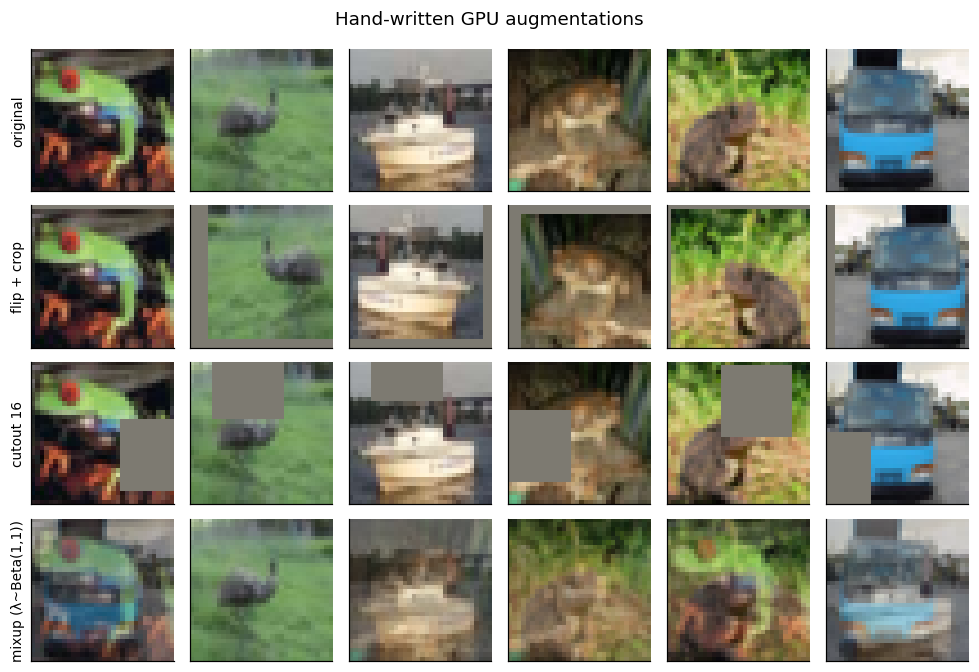

In [5]:
# Sanity check of the hand-written augmentations
set_seed()
demo = X_train[:6]
views = OrderedDict([('original', demo), ('flip + crop', random_crop(random_flip(demo))),
                     ('cutout 16', cutout(demo, 16)), ('mixup (λ~Beta(1,1))', mixup(demo, y_train[:6], 1.0)[0])])
fig, axes = plt.subplots(len(views), 6, figsize=(9, 6.2))
for r, (name, imgs) in enumerate(views.items()):
    for c in range(6):
        axes[r, c].imshow(denormalize(imgs[c][None])[0].permute(1, 2, 0))
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(name, fontsize=9)
plt.suptitle('Hand-written GPU augmentations')
plt.tight_layout()
plt.show()

The grid confirms the augmentations behave as intended. Crops shift the image by up to 4 pixels and fill the border with the mean colour (zero after normalisation). Cutout removes one 16×16 square, which is sometimes clipped at the image border. Mixup blends each image with another image from the same batch.

---
## Task 1: Backpropagation from scratch

The following layers are implemented with explicit `forward` / `backward` methods. **Autograd is not used**: no tensor has `requires_grad`, and training runs inside `torch.no_grad()`. Here $N$ is the batch size, rows are samples, $\delta = \partial L/\partial(\text{output})$ is the upstream gradient, and $\odot$ is the element-wise product.

| layer | forward | backward |
|---|---|---|
| Linear | $Y = XW + b$ | $\partial L/\partial W = X^\top\delta,\;\; \partial L/\partial b = \sum_n \delta_n,\;\; \partial L/\partial X = \delta W^\top$ |
| ReLU | $Y=\max(0,X)$ | $\partial L/\partial X = \delta \odot \mathbb 1[X>0]$ |
| Sigmoid (for 1d) | $Y=\sigma(X)$ | $\partial L/\partial X = \delta\odot \sigma(X)(1-\sigma(X))$ |
| Softmax + CE | $L = \frac1N\sum_n\big(\log\sum_k e^{z_{nk}} - z_{n,y_n}\big)$ | $\partial L/\partial Z = \frac1N\big(\mathrm{softmax}(Z) - \mathrm{onehot}(y)\big)$ |

The softmax cross-entropy subtracts the row maximum before exponentiating (the log-sum-exp trick). This changes nothing mathematically but prevents overflow. Weights use He initialisation, $\mathcal N(0, 2/n_\text{in})$, for ReLU networks and Xavier/Glorot initialisation, $\mathcal N(0, 2/(n_\text{in}+n_\text{out}))$, for sigmoid networks.

### 1(a) Layers and MLP

In [6]:
class Linear:
    def __init__(self, n_in, n_out, init='he', dtype=torch.float32):
        std = math.sqrt(2.0 / n_in) if init == 'he' else math.sqrt(2.0 / (n_in + n_out))  # He or Xavier
        self.params = {'W': torch.randn(n_in, n_out, dtype=dtype, device=device) * std,
                       'b': torch.zeros(n_out, dtype=dtype, device=device)}
        self.grads = {}

    def forward(self, x):
        self.x = x                                  # cache the input for the backward pass
        return x @ self.params['W'] + self.params['b']

    def backward(self, dout):
        self.dout = dout                            # kept only for the analysis in 1(d)
        self.grads['W'] = self.x.T @ dout
        self.grads['b'] = dout.sum(0)
        return dout @ self.params['W'].T


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class Sigmoid:
    def forward(self, x):
        self.s = 1.0 / (1.0 + torch.exp(-x))
        return self.s

    def backward(self, dout):
        return dout * self.s * (1.0 - self.s)


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values          # log-sum-exp trick
        log_probs = z - z.exp().sum(dim=1, keepdim=True).log()
        self.probs, self.y = log_probs.exp(), y
        return -log_probs[torch.arange(len(y), device=y.device), y].mean()

    def backward(self):
        n = len(self.y)
        d = self.probs.clone()
        d[torch.arange(n, device=d.device), self.y] -= 1.0
        return d / n


class MLP:
    """Fully-connected network: Linear -> act -> ... -> Linear, with softmax cross-entropy."""
    def __init__(self, sizes, act='relu', init='he', dtype=torch.float32):
        self.layers = []
        for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(n_in, n_out, init, dtype))
            if i < len(sizes) - 2:
                self.layers.append(ReLU() if act == 'relu' else Sigmoid())
        self.criterion = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.criterion.forward(self.forward(x), y)

    def backward(self):
        """Backpropagate dL/dlogits through every layer; returns dL/dx (gradient w.r.t. the input)."""
        d = self.criterion.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)
        return d

    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def sgd_step(self, lr):
        for lin in self.linears():
            for k in lin.params:
                lin.params[k] -= lr * lin.grads[k]

### 1(b) Gradient check: autograd and centred finite differences

Two checks are made for every parameter tensor and for the input:

* **Autograd.** The same network is rebuilt from *the same weights* using standard PyTorch ops, and `torch.autograd.grad` gives the reference gradient.
* **Centred finite differences.** $\displaystyle \frac{\partial L}{\partial\theta_i}\approx\frac{L(\theta_i+h)-L(\theta_i-h)}{2h}$, with truncation error $O(h^2)$.

The reported error is the relative error $\|g_\text{manual}-g_\text{ref}\|_2 \,/\, (\|g_\text{manual}\|_2+\|g_\text{ref}\|_2)$, together with the result of `torch.allclose`. The checks run in **float64**. In float32 the rounding error of each loss evaluation (~$10^{-7}$) is divided by $2h$, which swamps the finite-difference estimate (shown at the end of this section).

Two networks are checked:
1. a tiny network (input 20 → 16 → 16 → 10, batch 8), where *every* parameter is checked by finite differences, once with ReLU and once with sigmoid;
2. the full-size MLP used in 1(c) (3072 → 1024 → 512 → 10) on 64 real CIFAR images. Autograd checks every entry here, and finite differences check 30 random entries per tensor, since checking all ~3.7M would take too long.

In [7]:
def rel_error(a, b):
    return ((a - b).norm() / (a.norm() + b.norm()).clamp_min(1e-30)).item()

def manual_grads(mlp, x, y):
    mlp.loss(x, y)
    dx = mlp.backward()
    g = OrderedDict()
    for i, lin in enumerate(mlp.linears(), 1):
        g[f'W{i}'], g[f'b{i}'] = lin.grads['W'].clone(), lin.grads['b'].clone()
    g['x (input)'] = dx.clone()
    return g

def autograd_grads(mlp, x, y):
    """Reference: the same forward pass written with standard PyTorch ops, differentiated by autograd."""
    with torch.enable_grad():
        leaves, names = [], []
        xg = x.clone().requires_grad_(True)
        h, i = xg, 0
        for layer in mlp.layers:
            if isinstance(layer, Linear):
                i += 1
                W = layer.params['W'].clone().requires_grad_(True)
                b = layer.params['b'].clone().requires_grad_(True)
                leaves += [W, b]; names += [f'W{i}', f'b{i}']
                h = h @ W + b
            elif isinstance(layer, ReLU):
                h = torch.relu(h)
            else:
                h = torch.sigmoid(h)
        loss = F.cross_entropy(h, y)
        grads = torch.autograd.grad(loss, leaves + [xg])
    return OrderedDict(zip(names + ['x (input)'], grads))

def fd_grads(mlp, x, y, tensor, idx, h):
    """Centred finite differences of the loss w.r.t. tensor.view(-1)[idx]."""
    flat, out = tensor.view(-1), []
    for i in idx.tolist():
        old = flat[i].item()
        flat[i] = old + h; lp = mlp.loss(x, y).item()
        flat[i] = old - h; lm = mlp.loss(x, y).item()
        flat[i] = old
        out.append((lp - lm) / (2 * h))
    return torch.tensor(out, dtype=tensor.dtype, device=tensor.device)

def gradient_check(net_name, sizes, act, x, y, n_fd=None, h=1e-6, seed=0, dtype=torch.float64):
    torch.manual_seed(seed)
    mlp = MLP(sizes, act=act, init='he' if act == 'relu' else 'xavier', dtype=dtype)
    x = x.to(dtype).clone()
    g_man = manual_grads(mlp, x, y)
    g_auto = autograd_grads(mlp, x, y)
    targets = {f'{k}{i}': lin.params[k] for i, lin in enumerate(mlp.linears(), 1) for k in ('W', 'b')}
    targets['x (input)'] = x
    gen = torch.Generator().manual_seed(seed)
    rows = []
    for name, g in g_man.items():
        t = targets[name]
        idx = torch.arange(t.numel()) if (n_fd is None or t.numel() <= n_fd) else torch.randperm(t.numel(), generator=gen)[:n_fd]
        num = fd_grads(mlp, x, y, t, idx, h)
        ana = g.reshape(-1)[idx.to(device)]
        rows.append({'network': net_name, 'tensor': name, 'shape': tuple(g.shape),
                     'rel. err vs autograd': rel_error(g, g_auto[name]),
                     'allclose (autograd)': torch.allclose(g, g_auto[name]),
                     'entries checked by FD': len(idx),
                     'rel. err vs finite diff.': rel_error(ana, num),
                     'allclose (FD)': torch.allclose(ana, num, rtol=1e-5, atol=1e-8)})
    return rows

with torch.no_grad():
    gen = torch.Generator(device=device).manual_seed(0)
    x_tiny = torch.randn(8, 20, device=device, generator=gen)
    y_tiny = torch.randint(0, 10, (8,), device=device, generator=gen)
    rows = gradient_check('tiny ReLU MLP', [20, 16, 16, 10], 'relu', x_tiny, y_tiny)
    rows += gradient_check('tiny sigmoid MLP', [20, 16, 16, 10], 'sigmoid', x_tiny, y_tiny)
    x_big, y_big = X_train[:64].flatten(1), y_train[:64]
    rows += gradient_check('full MLP (CIFAR batch)', [3072, 1024, 512, 10], 'relu', x_big, y_big, n_fd=30)

gc = pd.DataFrame(rows)
for col in ('rel. err vs autograd', 'rel. err vs finite diff.'):
    gc[col] = gc[col].map(lambda v: f'{v:.2e}')
display(gc)
print('All allclose checks passed:', bool(pd.DataFrame(rows)[['allclose (autograd)', 'allclose (FD)']].all().all()))

,network,tensor,shape,rel. err vs autograd,allclose (autograd),entries checked by FD,rel. err vs finite diff.,allclose (FD)
0,tiny ReLU MLP,W1,"(20, 16)",0.00e+00,True,320,8.30e-10,True
1,tiny ReLU MLP,b1,"(16,)",0.00e+00,True,16,6.79e-10,True
2,tiny ReLU MLP,W2,"(16, 16)",0.00e+00,True,256,6.00e-10,True
3,tiny ReLU MLP,b2,"(16,)",0.00e+00,True,16,5.03e-10,True
4,tiny ReLU MLP,W3,"(16, 10)",0.00e+00,True,160,6.37e-10,True
5,tiny ReLU MLP,b3,"(10,)",0.00e+00,True,10,4.34e-10,True
6,tiny ReLU MLP,x (input),"(8, 20)",0.00e+00,True,160,1.39e-09,True
7,tiny sigmoid MLP,W1,"(20, 16)",1.11e-16,True,320,1.30e-08,True
8,tiny sigmoid MLP,b1,"(16,)",9.22e-17,True,16,1.13e-08,True
9,tiny sigmoid MLP,W2,"(16, 16)",7.25e-17,True,256,4.56e-09,True


All allclose checks passed: True


In [8]:
# Why float64? The same finite-difference check in float32 (h = 1e-3, a sensible float32 step)
with torch.no_grad():
    rows32 = gradient_check('tiny ReLU MLP, float32', [20, 16, 16, 10], 'relu', x_tiny, y_tiny, h=1e-3, dtype=torch.float32)
print('float32 relative errors vs finite differences:',
      ', '.join(f"{r['tensor']}: {r['rel. err vs finite diff.']:.1e}" for r in rows32))

float32 relative errors vs finite differences: W1: 3.2e-04, b1: 3.5e-04, W2: 3.0e-04, b2: 2.9e-04, W3: 3.3e-04, b3: 4.7e-04, x (input): 7.7e-04


**Interpretation.** For every weight, bias and input gradient, the manual gradients agree with autograd either exactly (relative error 0) or to ≤ $1.2\times10^{-16}$, which is float64 machine precision. So the hand-derived backward formulas compute exactly the derivatives autograd computes; the tiny differences in the sigmoid network come from evaluating $\sigma(1-\sigma)$ in a different order. The centred finite differences agree to about $4\times10^{-10}$–$4\times10^{-8}$ for the tiny networks and $4\times10^{-10}$–$2\times10^{-7}$ for the full 3.7M-parameter MLP. That is the expected size: it is bounded by the truncation error $O(h^2)\approx10^{-12}$ plus the rounding error $\approx\epsilon_\text{mach}|L|/h\approx10^{-10}$ relative to gradient entries that are themselves small. Every `torch.allclose` check passes, for ReLU and sigmoid, and for both the tiny network (every parameter checked) and the CIFAR-sized network.

The float32 run shows why the check needs double precision. With only ~7 significant digits, the difference $L(\theta+h)-L(\theta-h)$ loses most of its precision to cancellation. The relative errors rise to $3$–$8\times10^{-4}$, five orders of magnitude worse, even though the analytic gradient is identical.

### 1(c) Training the MLP with SGD on flattened CIFAR-10

The network is 3072 → 1024 → 512 → 10 with ReLU and He initialisation (≈3.7M parameters), trained by plain mini-batch SGD with my own update `θ ← θ − η∇θL`: batch size 128, 30 epochs, learning rate η = 0.01. Everything runs inside `torch.no_grad()`, so autograd plays no part.

epoch  1 | train loss 1.5411 acc 0.4644 | val loss 1.6337 acc 0.4302
epoch  5 | train loss 1.1842 acc 0.5965 | val loss 1.4752 acc 0.4872
epoch 10 | train loss 0.8945 acc 0.7188 | val loss 1.4182 acc 0.5028
epoch 15 | train loss 0.6708 acc 0.8054 | val loss 1.4316 acc 0.5196
epoch 20 | train loss 0.5181 acc 0.8573 | val loss 1.5304 acc 0.5136
epoch 25 | train loss 0.3585 acc 0.9200 | val loss 1.5963 acc 0.5122
epoch 30 | train loss 0.2330 acc 0.9611 | val loss 1.6631 acc 0.5202


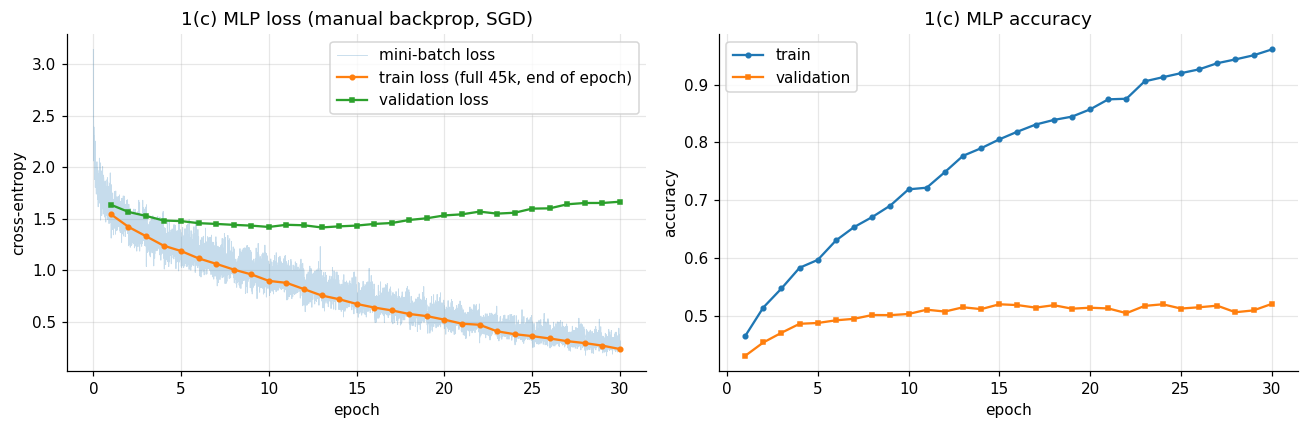

final validation accuracy: 0.5202 | best: 0.5202 (epoch 30) | final train accuracy: 0.9611


In [9]:
def mlp_evaluate(mlp, X, y, bs=5000):
    loss_sum, correct = 0.0, 0
    for i in range(0, len(X), bs):
        logits = mlp.forward(X[i:i + bs])
        loss_sum += mlp.criterion.forward(logits, y[i:i + bs]).item() * len(logits)
        correct += (logits.argmax(1) == y[i:i + bs]).sum().item()
    return loss_sum / len(X), correct / len(X)

def train_manual_mlp(sizes=(3072, 1024, 512, 10), lr=0.01, epochs=30, batch_size=128, seed=SEED):
    set_seed(seed)
    mlp = MLP(list(sizes), act='relu', init='he')
    Xtr, Xva = X_train.flatten(1), X_val.flatten(1)
    hist = {k: [] for k in ('iter_loss', 'train_loss', 'train_acc', 'val_loss', 'val_acc')}
    with torch.no_grad():                                   # no autograd anywhere in this loop
        for ep in range(epochs):
            for xb, yb in batches(Xtr, y_train, batch_size, drop_last=True):
                loss = mlp.loss(xb, yb)
                mlp.backward()
                mlp.sgd_step(lr)
                hist['iter_loss'].append(loss.item())
            tl, ta = mlp_evaluate(mlp, Xtr, y_train)
            vl, va = mlp_evaluate(mlp, Xva, y_val)
            for k, v in zip(('train_loss', 'train_acc', 'val_loss', 'val_acc'), (tl, ta, vl, va)):
                hist[k].append(v)
            if (ep + 1) % 5 == 0 or ep == 0 or ep == epochs - 1:
                print(f'epoch {ep + 1:2d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}')
    return hist

T1C_EPOCHS = 30
h1c = cached('t1c_mlp', lambda: train_manual_mlp(epochs=E(T1C_EPOCHS)))

ep = np.arange(1, len(h1c['val_acc']) + 1)
ipe = len(h1c['iter_loss']) / len(ep)          # iterations per epoch
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.arange(len(h1c['iter_loss'])) / ipe, h1c['iter_loss'], alpha=0.25, lw=0.6, label='mini-batch loss')
ax[0].plot(ep, h1c['train_loss'], 'o-', ms=3, label='train loss (full 45k, end of epoch)')
ax[0].plot(ep, h1c['val_loss'], 's-', ms=3, label='validation loss')
ax[0].set(xlabel='epoch', ylabel='cross-entropy', title='1(c) MLP loss (manual backprop, SGD)')
ax[0].legend()
ax[1].plot(ep, h1c['train_acc'], 'o-', ms=3, label='train')
ax[1].plot(ep, h1c['val_acc'], 's-', ms=3, label='validation')
ax[1].set(xlabel='epoch', ylabel='accuracy', title='1(c) MLP accuracy')
ax[1].legend()
plt.tight_layout()
plt.show()
best = int(np.argmax(h1c['val_acc']))
print(f"final validation accuracy: {h1c['val_acc'][-1]:.4f} | best: {h1c['val_acc'][best]:.4f} (epoch {best + 1}) | "
      f"final train accuracy: {h1c['train_acc'][-1]:.4f}")

**Interpretation.** The mini-batch loss starts near $\ln 10 \approx 2.30$, the value for a uniform 10-way guess, and falls quickly. Validation accuracy reaches about 49% by epoch 5 and ends at **52.0%**, which is also its best value. From about epoch 13 on it only moves between 51% and 52%. That is typical for an MLP on raw CIFAR-10 pixels. The two curves also expose the MLP's weakness, **overfitting**:
* training accuracy keeps climbing to **96.1%** and training loss falls to 0.23;
* the validation loss reaches its minimum (≈1.42) around **epoch 10–13** and then *rises* to 1.66, while validation accuracy stays flat at about 51–52%.

After epoch ~13 the network is mostly memorising the 45k training images, and it becomes more confident on the validation images it gets wrong, so the loss rises even though accuracy does not change. The underlying reason is that flattening throws away the 2-D structure of the image. Every pixel–weight pair is independent, so the model cannot share weights across positions or become translation-invariant, and its ≈3.7M parameters make memorisation easy. The CNNs in Tasks 2–4 fix exactly this: a 141k-parameter CNN reaches more than 76% in 15 epochs (Task 2c).

### 1(d) Per-layer gradient norms at initialisation: 10-layer MLP, sigmoid vs ReLU

The 10-layer MLP is 3072 → 256 (×9 hidden layers) → 10, i.e. 10 weight matrices. A single batch of 512 training images is pushed through it, the gradient is backpropagated **with the manual implementation**, and $\|\partial L/\partial W_\ell\|_F$ is recorded for every layer. To separate the effect of the *activation* from that of the *initialisation*, both activations are tested with both He and Xavier initialisation. Curves are the mean over 5 random initialisations; the shaded band is the min–max range.

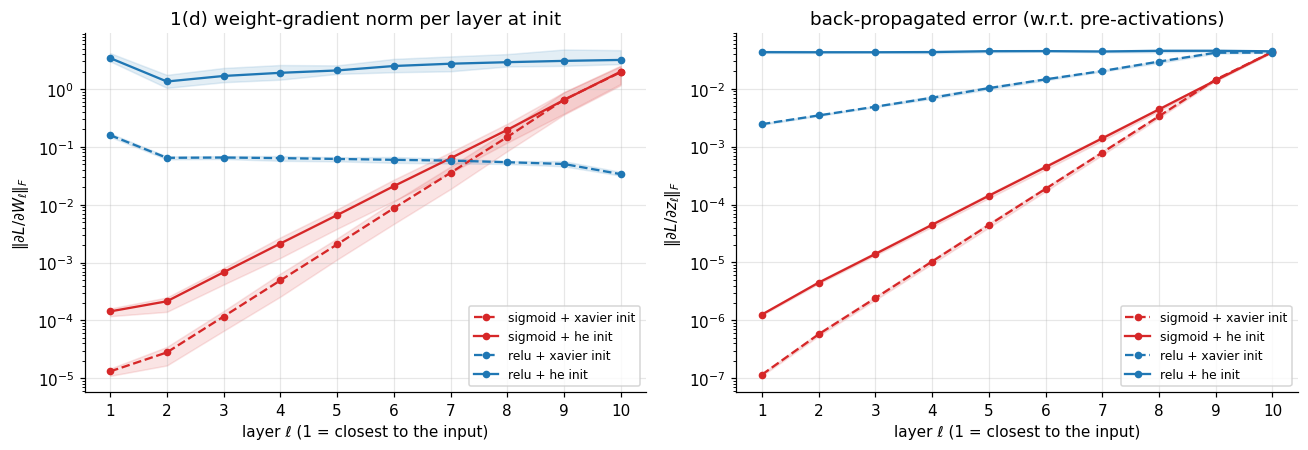

,‖∇W₁‖ (first layer),‖∇W₁₀‖ (last layer),ratio first / last
sigmoid + xavier,1.31e-05,1.95e+00,6.73e-06
sigmoid + he,1.43e-04,1.99e+00,7.18e-05
relu + xavier,1.59e-01,3.37e-02,4.72e+00
relu + he,3.42e+00,3.18e+00,1.08e+00


In [10]:
def grad_norms_at_init(act, init, depth=10, width=256, n=512, seeds=range(5)):
    xb, yb = X_train[:n].flatten(1), y_train[:n]
    w_norms, delta_norms = [], []
    with torch.no_grad():
        for s in seeds:
            torch.manual_seed(s)
            mlp = MLP([xb.shape[1]] + [width] * (depth - 1) + [10], act=act, init=init)
            mlp.loss(xb, yb)
            mlp.backward()
            w_norms.append([lin.grads['W'].norm().item() for lin in mlp.linears()])
            delta_norms.append([lin.dout.norm().item() for lin in mlp.linears()])   # ||dL/d(pre-activation)||
    return np.array(w_norms), np.array(delta_norms)

settings = [('sigmoid', 'xavier'), ('sigmoid', 'he'), ('relu', 'xavier'), ('relu', 'he')]
style = {'sigmoid': 'tab:red', 'relu': 'tab:blue', 'xavier': '--', 'he': '-'}
res1d = {s: grad_norms_at_init(*s) for s in settings}

layers = np.arange(1, 11)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for (act, init), (wn, dn) in res1d.items():
    for a, arr in zip(ax, (wn, dn)):
        a.plot(layers, arr.mean(0), style[init], color=style[act], marker='o', ms=4, label=f'{act} + {init} init')
        a.fill_between(layers, arr.min(0), arr.max(0), color=style[act], alpha=0.12)
for a in ax:
    a.set_yscale('log'); a.set_xticks(layers); a.set_xlabel('layer ℓ (1 = closest to the input)'); a.legend(fontsize=8)
ax[0].set(ylabel=r'$\|\partial L/\partial W_\ell\|_F$', title='1(d) weight-gradient norm per layer at init')
ax[1].set(ylabel=r'$\|\partial L/\partial z_\ell\|_F$', title='back-propagated error (w.r.t. pre-activations)')
plt.tight_layout()
plt.show()

tbl = pd.DataFrame({f'{a} + {i}': {'‖∇W₁‖ (first layer)': wn.mean(0)[0], '‖∇W₁₀‖ (last layer)': wn.mean(0)[-1],
                                   'ratio first / last': wn.mean(0)[0] / wn.mean(0)[-1]}
                    for (a, i), (wn, _) in res1d.items()}).T
display(tbl.map(lambda v: f'{v:.2e}'))

**Interpretation.** Backpropagation multiplies the error signal at each layer by $W_\ell^\top$ and by the activation derivative: $\delta_{\ell-1} = (\delta_\ell W_\ell^\top)\odot f'(z_{\ell-1})$. The weight gradient is $\nabla W_\ell = a_{\ell-1}^\top \delta_\ell$.

* **Sigmoid: vanishing gradients.** The gradient norm falls by a constant factor at every layer from the output back towards the input, which shows up as a straight line on the log scale. With Xavier initialisation, $\|\nabla W_1\| \approx 1.3\times10^{-5}$ against $\|\nabla W_{10}\| \approx 2.0$, a ratio of **$7\times10^{-6}$**. The first layer gets a gradient about 150,000 times smaller than the last, so it would barely learn. The cause is $\sigma'(z)=\sigma(z)(1-\sigma(z)) \le 1/4$. Near $z=0$ it is ≈ 0.25, so every layer multiplies the back-propagated error by roughly $0.25\cdot\|W\|<1$. The right-hand plot shows this directly: $\|\delta_\ell\|$ falls by about 4× per layer, i.e. about 6 orders of magnitude over 9 layers. He initialisation (solid red) has larger weights and so slows the decay by only about one order of magnitude overall (ratio $7.2\times10^{-5}$). The decay is built into the bounded derivative, so no weight scale removes it.
* **ReLU + He: healthy gradient flow.** The gradient norm is about the same in every layer: 3.4 for the first and 3.2 for the last (ratio 1.08), and $\|\delta_\ell\|$ is flat. ReLU's derivative is exactly 1 for the active units, and He initialisation ($\mathrm{Var}\,W = 2/n_\text{in}$) is derived precisely so that $\mathrm{Var}(\delta)$ is preserved from layer to layer: the factor 2 compensates for the half of the units that ReLU switches off. Every layer gets a useful learning signal.
* **ReLU + Xavier** is an informative control. The back-propagated error $\|\delta_\ell\|$ (right, dashed blue) shrinks steadily towards the input, by about 17× over 9 layers, because Xavier's variance is about half of what ReLU needs. Yet the *weight* gradients (left) stay roughly flat at about 0.06, because the forward activations shrink in the opposite direction and the two effects cancel in $\nabla W_\ell = a_{\ell-1}^\top\delta_\ell$. For ReLU, then, the initialisation mainly sets the *overall* scale (0.06 instead of about 3), whereas for sigmoid the decay with depth is unavoidable.

This is why deep networks use ReLU-type activations with He initialisation, plus batch normalisation and residual connections (Task 3b), which keep gradient magnitudes healthy as depth increases.

---
## Task 2: Optimizers

### 2(a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

Both follow PyTorch's exact conventions, so the results can match to floating-point precision:

* **SGD with momentum** (dampening 0): $g \leftarrow \nabla\theta + \lambda\theta$ (weight decay), $\;v \leftarrow \mu v + g$ (with $v_1 = g_1$), $\;\theta \leftarrow \theta - \eta v$. With Nesterov momentum, $\theta \leftarrow \theta - \eta\,(g + \mu v)$. This is the "$v=\mu v+g$" form PyTorch uses, not the textbook $v = \mu v - \eta g$; the two are equivalent only for a constant learning rate.
* **Adam**: $m \leftarrow \beta_1 m + (1-\beta_1)g$, $\;s \leftarrow \beta_2 s + (1-\beta_2)g^2$. The **bias corrections** are $\hat m = m/(1-\beta_1^t)$ and $\hat s = s/(1-\beta_2^t)$, and the update is $\theta \leftarrow \theta - \eta\,\hat m/(\sqrt{\hat s}+\epsilon)$. The $\epsilon$ is added *after* the square root, as in PyTorch. Weight decay is L2 added to the gradient, as in `torch.optim.Adam`.

The bias correction matters because $m$ and $s$ start at 0. Without it the first updates would be biased towards zero, by a factor of 10 for $\beta_1 = 0.9$ at $t = 1$.

In [11]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-2, momentum=0.0, weight_decay=0.0, nesterov=False):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay, nesterov=nesterov))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd, nesterov = group['lr'], group['momentum'], group['weight_decay'], group['nesterov']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                if mu != 0:
                    state = self.state[p]
                    if 'momentum_buffer' not in state:
                        buf = state['momentum_buffer'] = g.clone()       # v_1 = g_1
                    else:
                        buf = state['momentum_buffer']
                        buf.mul_(mu).add_(g)                            # v = mu * v + g
                    g = g.add(buf, alpha=mu) if nesterov else buf
                p.add_(g, alpha=-lr)                                    # theta = theta - lr * v
        return loss


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group['lr'], group['betas'], group['eps'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)       # m
                    state['exp_avg_sq'] = torch.zeros_like(p)    # s
                state['step'] += 1
                t, m, s = state['step'], state['exp_avg'], state['exp_avg_sq']
                m.mul_(b1).add_(g, alpha=1 - b1)                  # m = b1 m + (1 - b1) g
                s.mul_(b2).addcmul_(g, g, value=1 - b2)           # s = b2 s + (1 - b2) g^2
                bc1, bc2 = 1 - b1 ** t, 1 - b2 ** t               # bias corrections
                denom = (s.sqrt() / math.sqrt(bc2)).add_(eps)     # sqrt(s_hat) + eps
                p.addcdiv_(m, denom, value=-lr / bc1)             # theta -= lr * m_hat / denom
        return loss

**Showing that they match PyTorch.** Two identical copies of a small CNN, in float64 with the same initial weights, are trained for 100 steps on the same CIFAR mini-batches: one with my optimizer and one with the PyTorch optimizer. After every step the largest absolute difference between any pair of corresponding parameters is recorded. Several hyper-parameter settings are tested: plain SGD, momentum, Nesterov, weight decay, and non-default Adam betas.

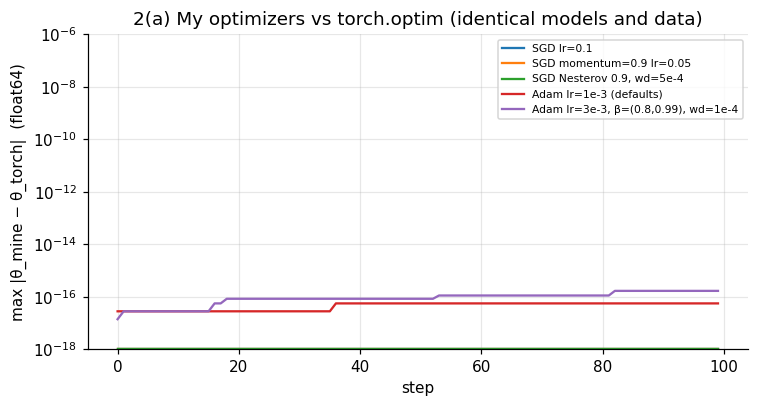

,setting,max |Δθ| after 100 steps,max |Δθ| over all steps,torch.allclose
0,SGD lr=0.1,0.00e+00,0.00e+00,True
1,SGD momentum=0.9 lr=0.05,0.00e+00,0.00e+00,True
2,"SGD Nesterov 0.9, wd=5e-4",0.00e+00,0.00e+00,True
3,Adam lr=1e-3 (defaults),5.55e-17,5.55e-17,True
4,"Adam lr=3e-3, β=(0.8,0.99), wd=1e-4",1.67e-16,1.67e-16,True


In [12]:
def tiny_cnn():
    return nn.Sequential(nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
                         nn.Flatten(), nn.Linear(16, 10))

def compare_with_torch(mine, ref, kwargs, steps=100, bs=64):
    torch.manual_seed(0)
    m1 = tiny_cnn().double().to(device)
    m2 = copy.deepcopy(m1)
    o1, o2 = mine(m1.parameters(), **kwargs), ref(m2.parameters(), **kwargs)
    gen = torch.Generator(device=device).manual_seed(0)
    diffs = []
    for _ in range(steps):
        idx = torch.randint(0, len(X_train), (bs,), device=device, generator=gen)
        xb, yb = X_train[idx].double(), y_train[idx]
        for model, opt in ((m1, o1), (m2, o2)):
            opt.zero_grad()
            F.cross_entropy(model(xb), yb).backward()
            opt.step()
        diffs.append(max((p1 - p2).abs().max().item() for p1, p2 in zip(m1.parameters(), m2.parameters())))
    close = all(torch.allclose(p1, p2, rtol=1e-7, atol=1e-10) for p1, p2 in zip(m1.parameters(), m2.parameters()))
    return diffs, close

opt_tests = OrderedDict([
    ('SGD lr=0.1',                         (MySGD,  torch.optim.SGD,  dict(lr=0.1))),
    ('SGD momentum=0.9 lr=0.05',           (MySGD,  torch.optim.SGD,  dict(lr=0.05, momentum=0.9))),
    ('SGD Nesterov 0.9, wd=5e-4',          (MySGD,  torch.optim.SGD,  dict(lr=0.05, momentum=0.9, nesterov=True, weight_decay=5e-4))),
    ('Adam lr=1e-3 (defaults)',            (MyAdam, torch.optim.Adam, dict(lr=1e-3))),
    ('Adam lr=3e-3, β=(0.8,0.99), wd=1e-4', (MyAdam, torch.optim.Adam, dict(lr=3e-3, betas=(0.8, 0.99), weight_decay=1e-4))),
])
rows = []
plt.figure(figsize=(7, 3.8))
for name, (mine, ref, kw) in opt_tests.items():
    diffs, close = compare_with_torch(mine, ref, kw)
    plt.plot(np.maximum(diffs, 1e-18), label=name)
    rows.append({'setting': name, 'max |Δθ| after 100 steps': f'{diffs[-1]:.2e}',
                 'max |Δθ| over all steps': f'{max(diffs):.2e}', 'torch.allclose': close})
plt.yscale('log'); plt.ylim(1e-18, 1e-6)
plt.xlabel('step'); plt.ylabel('max |θ_mine − θ_torch|  (float64)')
plt.title('2(a) My optimizers vs torch.optim (identical models and data)')
plt.legend(fontsize=7)
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows))

**Interpretation.** The three SGD variants are **bit-for-bit identical** to `torch.optim.SGD` after 100 steps (max difference exactly 0, drawn at the bottom of the plot). My Adam differs from `torch.optim.Adam` by at most $1.7\times10^{-16}$, which is a last-bit rounding difference: PyTorch updates $m$ with `lerp_` while I use `mul_` + `add_`, which is mathematically the same. `torch.allclose` holds in every setting. So the implementations are the same algorithm, including momentum-buffer initialisation, Nesterov, weight decay, non-default betas and Adam's bias correction. A wrong detail, such as $\epsilon$ inside the square root or a missing bias correction, would give differences of order $10^{-4}$ or more within a few steps.

### 2(b) Trajectories on $f(x,y)=\tfrac12(x^2+50y^2)$

The Hessian is $\mathrm{diag}(1, 50)$, so the function is a long, narrow valley: 50 times steeper in $y$ than in $x$ (condition number $\kappa = 50$). The gradient is $(x, 50y)$, and every method starts from $(-10, 1)$. Gradient descent is stable only if $\eta < 2/\lambda_\max = 2/50 = 0.04$. Each optimizer gets a learning rate that works well for it: SGD $\eta=0.035$, close to the optimal constant step $2/(\lambda_\min+\lambda_\max)=0.039$; SGD + momentum $\eta = 0.01$, $\mu = 0.9$; Adam $\eta = 0.3$. All runs use my optimizer classes from 2(a). For comparison, SGD with $\eta = 0.041$, just above the stability limit, is also shown in the loss plot.

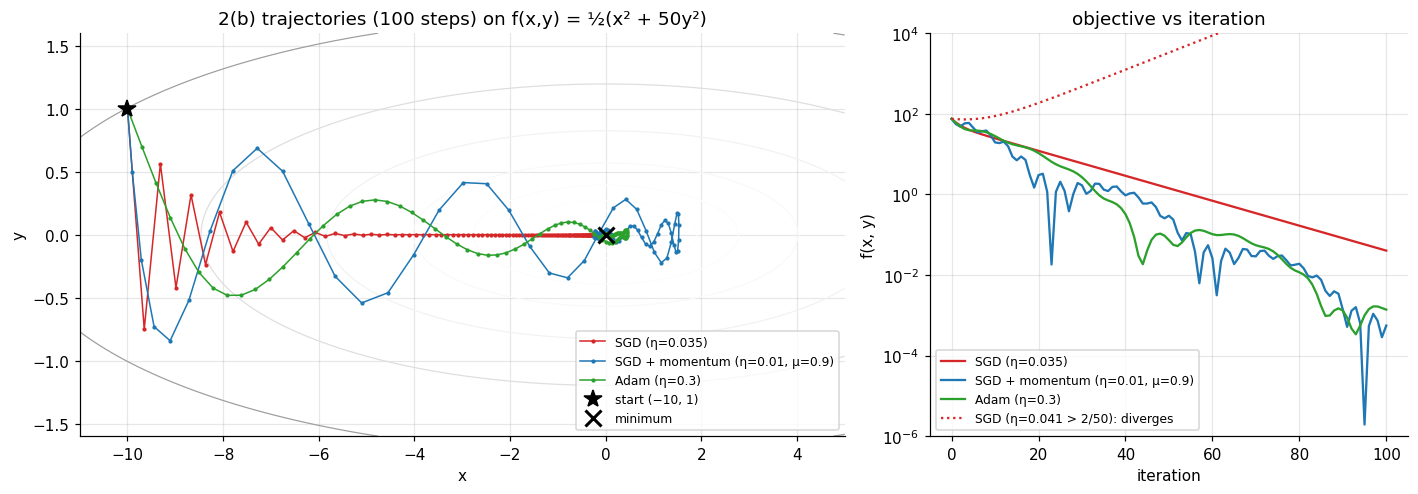

SGD (η=0.035)                    f after 25 / 50 / 100 steps: 8.42e+00 / 1.42e+00 / 4.02e-02
SGD + momentum (η=0.01, μ=0.9)   f after 25 / 50 / 100 steps: 2.06e+00 / 2.95e-01 / 5.56e-04
Adam (η=0.3)                     f after 25 / 50 / 100 steps: 4.99e+00 / 7.31e-02 / 1.38e-03


In [13]:
def quadratic(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def trajectory(opt_cls, steps=100, start=(-10.0, 1.0), **kw):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_cls([p], **kw)
    pts = [p.detach().clone()]
    for _ in range(steps):
        opt.zero_grad()
        quadratic(p).backward()
        opt.step()
        pts.append(p.detach().clone())
    return torch.stack(pts).numpy()

traj_runs = OrderedDict([
    ('SGD (η=0.035)',                (MySGD,  dict(lr=0.035),              'tab:red')),
    ('SGD + momentum (η=0.01, μ=0.9)', (MySGD,  dict(lr=0.01, momentum=0.9), 'tab:blue')),
    ('Adam (η=0.3)',                 (MyAdam, dict(lr=0.3),                'tab:green')),
])
trajs = {name: trajectory(cls, **kw) for name, (cls, kw, _) in traj_runs.items()}
unstable = trajectory(MySGD, lr=0.041)

xs, ys = np.meshgrid(np.linspace(-11, 5, 400), np.linspace(-1.6, 1.6, 400))
zs = 0.5 * (xs ** 2 + 50 * ys ** 2)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.6, 1]})
cs = ax[0].contour(xs, ys, zs, levels=np.logspace(-2, 2.2, 14), cmap='Greys', linewidths=0.8)
for name, (_, _, col) in traj_runs.items():
    t = trajs[name]
    ax[0].plot(t[:, 0], t[:, 1], '.-', color=col, ms=3.5, lw=1, label=name)
ax[0].plot(-10, 1, 'k*', ms=12, label='start (−10, 1)')
ax[0].plot(0, 0, 'kx', ms=10, mew=2, label='minimum')
ax[0].set(xlabel='x', ylabel='y', title='2(b) trajectories (100 steps) on f(x,y) = ½(x² + 50y²)', ylim=(-1.6, 1.6))
ax[0].legend(fontsize=8, loc='lower right')
for name, (_, _, col) in traj_runs.items():
    ax[1].semilogy([quadratic(p) for p in trajs[name]], color=col, label=name)
ax[1].semilogy([quadratic(p) for p in unstable], ':', color='tab:red', label='SGD (η=0.041 > 2/50): diverges')
ax[1].set(xlabel='iteration', ylabel='f(x, y)', title='objective vs iteration', ylim=(1e-6, 1e4))
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
for name in trajs:
    print(f'{name:32s} f after 25 / 50 / 100 steps: ' +
          ' / '.join(f'{quadratic(trajs[name][k]):.2e}' for k in (25, 50, 100)))

**Interpretation.**
* **SGD** follows the negative gradient, which points almost entirely along the steep $y$ direction. With $\eta = 0.035$ the $y$ coordinate is multiplied by $1 - 50\eta = -0.75$ each step, so it **zig-zags** across the valley, flipping sign every step and dying out after about 15 steps. Along the flat $x$ direction it only shrinks by $1-\eta = 0.965$ per step, so it then **crawls** along the valley floor and ends 100 steps later at $f = 4\times10^{-2}$, still at $x\approx-0.3$. The loss falls as a straight line on the log scale, a constant linear rate set by the *smallest* curvature, while the step size is capped by the *largest* ($\eta<2/50$). The dotted curve shows that $\eta = 0.041$, just past that limit, makes the $y$ oscillation grow by $|1-50\eta| = 1.05$ per step, and SGD diverges. Ill-conditioning forces a step size that is far too small for the flat direction.
* **SGD with momentum** accumulates a velocity $v = \mu v + g$. The consistent $x$ gradients add up, giving an effective step of up to $\eta/(1-\mu) = 10\eta$ along the valley, so it advances along $x$ much faster than SGD. The price is a "heavy ball" that is under-damped: it oscillates across the valley with an amplitude decaying only like $\sqrt{\mu}^{\,t}\approx0.95^t$, overshoots the minimum to $x\approx+1.5$ and comes back. This gives the jagged, non-monotone loss curve, which still reaches $f=5.6\times10^{-4}$ after 100 steps, about 70× lower than SGD.
* **Adam** divides each coordinate's step by a running RMS of its own gradient, so at first both coordinates move by about $\eta$ per step regardless of their curvature. The trajectory therefore **heads diagonally** across the valley, not along the steepest-descent direction. The 50× difference in curvature is largely removed: Adam acts as a per-coordinate (diagonal) preconditioner. Its momentum ($\beta_1=0.9$) then carries it smoothly back and forth across the valley with a slowly decaying amplitude, because the normalised step does not shrink in proportion to the gradient near the minimum. It reaches $f=1.4\times10^{-3}$ after 100 steps.

Overall, momentum and Adam both handle the ill-conditioning much better than plain SGD, reaching a loss 30–70× lower after 100 steps. They use different mechanisms: momentum averages gradients over time, while Adam rescales each coordinate by its own gradient history. Both trade SGD's monotone progress for oscillation, which is why, in practice, they are combined with learning-rate decay.

### 2(c) Learning-rate sensitivity: a small CNN with each optimizer

**Model (`SmallCNN`).** Three stages, [conv3×3–ReLU]×2 + max-pool with 32 / 64 / 128 channels (only one conv in the last stage), followed by global average pooling and a linear classifier, with He initialisation. For this experiment it is used **without batch norm**. BN makes networks much less sensitive to the learning rate, which would hide exactly the optimizer differences we want to measure. Task 3a uses the same network with BN.

**Protocol.** Each optimizer (my implementations from 2(a)) is trained at three learning rates, one decade apart, for 15 epochs. Batch size is 128, with no augmentation, no weight decay and a constant learning rate, so that only the optimizer and its learning rate change. SGD and SGD+momentum share the same grid {0.003, 0.03, 0.3}, which makes the effective step $\eta/(1-\mu)$ of momentum directly visible. Adam uses {1e-4, 1e-3, 1e-2}, centred on its usual default of 1e-3. The metric is the best validation accuracy over the 15 epochs.

In [14]:
class SmallCNN(nn.Module):
    """3 stages of 3x3 convs (32-64-128 channels) + max-pool, global average pooling, linear classifier."""
    def __init__(self, bn=True, dropout=0.0, widths=(32, 64, 128)):
        super().__init__()
        def conv(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1, bias=not bn)]
            if bn:
                layers.append(nn.BatchNorm2d(cout))
            return layers + [nn.ReLU(inplace=True)]
        def drop():
            return [nn.Dropout(dropout)] if dropout > 0 else []
        c1, c2, c3 = widths
        self.features = nn.Sequential(
            *conv(3, c1), *conv(c1, c1), nn.MaxPool2d(2), *drop(),     # 32x32 -> 16x16
            *conv(c1, c2), *conv(c2, c2), nn.MaxPool2d(2), *drop(),    # 16x16 -> 8x8
            *conv(c2, c3), nn.MaxPool2d(2), *drop())                    # 8x8   -> 4x4
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), *drop(), nn.Linear(c3, 10))
        kaiming_init(self)

    def forward(self, x):
        return self.head(self.features(x))

print(f'SmallCNN parameters: {n_params(SmallCNN(bn=False)):,} (without BN), {n_params(SmallCNN(bn=True)):,} (with BN)')

SmallCNN parameters: 140,714 (without BN), 141,034 (with BN)


In [15]:
T2C_EPOCHS = 15
T2C_GRID = OrderedDict([
    ('SGD',          (lambda p, lr: MySGD(p, lr=lr),               [3e-3, 3e-2, 3e-1])),
    ('SGD+momentum', (lambda p, lr: MySGD(p, lr=lr, momentum=0.9), [3e-3, 3e-2, 3e-1])),
    ('Adam',         (lambda p, lr: MyAdam(p, lr=lr),              [1e-4, 1e-3, 1e-2])),
])

def run_t2c(make_opt, lr, tag):
    set_seed(SEED)
    model = SmallCNN(bn=False).to(device)
    return train(model, make_opt(model.parameters(), lr), E(T2C_EPOCHS), log_every=5, tag=tag)

t2c = OrderedDict()
for opt_name, (make_opt, lrs) in T2C_GRID.items():
    for lr in lrs:
        tag = f'{opt_name} lr={lr:g}'
        t2c[(opt_name, lr)] = cached(f't2c_{opt_name}_{lr:g}', lambda: run_t2c(make_opt, lr, tag))

          SGD lr=0.003 | ep   5/15 | train loss 1.6679 | val loss 1.6261 | val acc 0.4218
          SGD lr=0.003 | ep  10/15 | train loss 1.4942 | val loss 1.5092 | val acc 0.4688
          SGD lr=0.003 | ep  15/15 | train loss 1.3928 | val loss 1.3691 | val acc 0.5284
           SGD lr=0.03 | ep   5/15 | train loss 1.3662 | val loss 1.2832 | val acc 0.5514
           SGD lr=0.03 | ep  10/15 | train loss 1.0632 | val loss 1.0481 | val acc 0.6200
           SGD lr=0.03 | ep  15/15 | train loss 0.8832 | val loss 0.8961 | val acc 0.6900
            SGD lr=0.3 | ep   1/15 | train loss nan | val loss nan | val acc 0.0976
SGD lr=0.3: non-finite training loss -> diverged, stopping this run
 SGD+momentum lr=0.003 | ep   5/15 | train loss 1.2293 | val loss 1.2106 | val acc 0.5732
 SGD+momentum lr=0.003 | ep  10/15 | train loss 0.9364 | val loss 1.0083 | val acc 0.6460
 SGD+momentum lr=0.003 | ep  15/15 | train loss 0.7748 | val loss 0.8650 | val acc 0.6994
  SGD+momentum lr=0.03 | ep   5/15 | t

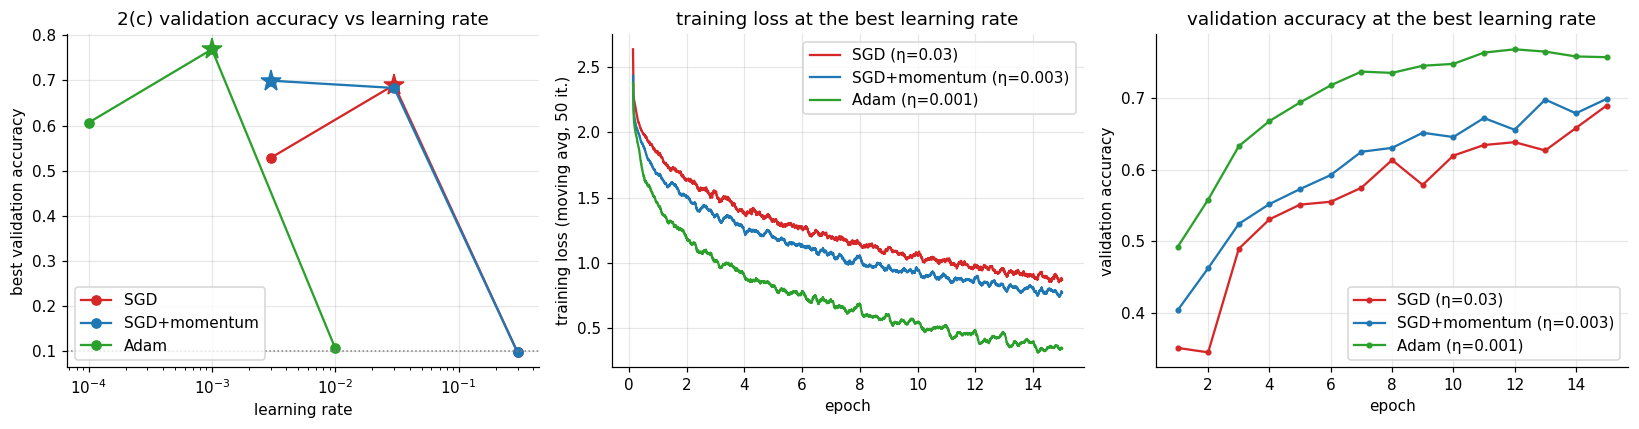

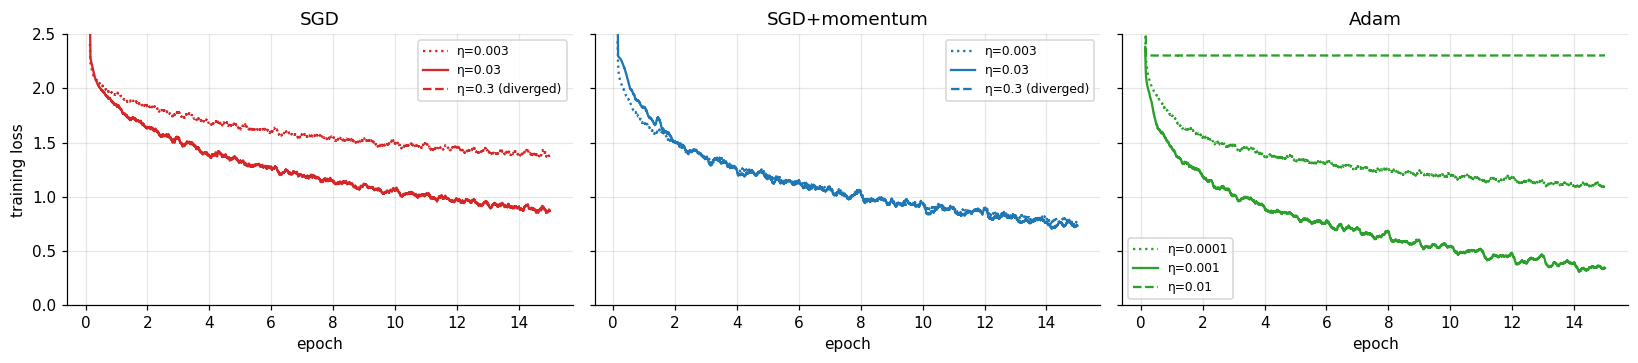

,optimizer,learning rate,best val acc,final val acc,final train loss,diverged
0,SGD,0.0030,0.5284,0.5284,1.3928,False
1,SGD,0.0300,0.6900,0.6900,0.8832,False
2,SGD,0.3000,0.0976,0.0976,NaN,True
3,SGD+momentum,0.0030,0.6994,0.6994,0.7748,False
4,SGD+momentum,0.0300,0.6832,0.6832,0.7394,False
5,SGD+momentum,0.3000,0.0976,0.0976,NaN,True
6,Adam,0.0001,0.6062,0.6062,1.1050,False
7,Adam,0.0010,0.7688,0.7578,0.3401,False
8,Adam,0.0100,0.1064,0.0976,2.3033,False


SGD          : best η = 0.03 -> 0.6900;  spread over the 3 learning rates = 0.5924
SGD+momentum : best η = 0.003 -> 0.6994;  spread over the 3 learning rates = 0.6018
Adam         : best η = 0.001 -> 0.7688;  spread over the 3 learning rates = 0.6624


In [16]:
colors = {'SGD': 'tab:red', 'SGD+momentum': 'tab:blue', 'Adam': 'tab:green'}
best_val = {k: max(h['val_acc']) for k, h in t2c.items()}
best_lr = {o: max(lrs, key=lambda lr: best_val[(o, lr)]) for o, (_, lrs) in T2C_GRID.items()}

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for o, (_, lrs) in T2C_GRID.items():
    ax[0].plot(lrs, [best_val[(o, lr)] for lr in lrs], 'o-', color=colors[o], label=o)
    ax[0].plot(best_lr[o], best_val[(o, best_lr[o])], '*', ms=14, color=colors[o])
ax[0].set_xscale('log'); ax[0].axhline(0.1, color='grey', ls=':', lw=1)
ax[0].set(xlabel='learning rate', ylabel='best validation accuracy', title='2(c) validation accuracy vs learning rate')
ax[0].legend()
for o in T2C_GRID:
    h = t2c[(o, best_lr[o])]
    ipe = len(h['iter_loss']) / len(h['train_loss'])
    sm = smooth(h['iter_loss'], 50)
    ax[1].plot((np.arange(len(sm)) + 50) / ipe, sm, color=colors[o], label=f'{o} (η={best_lr[o]:g})')
    ax[2].plot(np.arange(1, len(h['val_acc']) + 1), h['val_acc'], 'o-', ms=3, color=colors[o], label=f'{o} (η={best_lr[o]:g})')
ax[1].set(xlabel='epoch', ylabel='training loss (moving avg, 50 it.)', title='training loss at the best learning rate')
ax[2].set(xlabel='epoch', ylabel='validation accuracy', title='validation accuracy at the best learning rate')
ax[1].legend(); ax[2].legend()
plt.tight_layout()
plt.show()

# all nine training-loss curves, to see *how* each learning rate fails
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
for a, (o, (_, lrs)) in zip(ax, T2C_GRID.items()):
    for lr, ls in zip(lrs, (':', '-', '--')):
        h = t2c[(o, lr)]
        ipe = len(h['iter_loss']) / len(h['train_loss'])
        sm = smooth(h['iter_loss'], 50)
        a.plot((np.arange(len(sm)) + 50) / ipe, sm, ls, color=colors[o], label=f'η={lr:g}' + (' (diverged)' if h.get('diverged') else ''))
    a.set(title=o, xlabel='epoch', ylim=(0, 2.5)); a.legend(fontsize=8)
ax[0].set_ylabel('training loss')
plt.tight_layout()
plt.show()

tab = pd.DataFrame([{'optimizer': o, 'learning rate': lr,
                     'best val acc': best_val[(o, lr)],
                     'final val acc': t2c[(o, lr)]['val_acc'][-1],
                     'final train loss': t2c[(o, lr)]['train_loss'][-1],
                     'diverged': bool(t2c[(o, lr)].get('diverged', False))}
                    for o, (_, lrs) in T2C_GRID.items() for lr in lrs])
display(tab.round(4))
for o, (_, lrs) in T2C_GRID.items():
    accs = [best_val[(o, lr)] for lr in lrs]
    print(f'{o:13s}: best η = {best_lr[o]:g} -> {max(accs):.4f};  spread over the 3 learning rates = {max(accs) - min(accs):.4f}')

**Interpretation.**
* **Plain SGD**: 52.8% at η = 0.003 (too slow, with the training loss still at 1.39 after 15 epochs), **69.0% at η = 0.03**, and **divergence** at η = 0.3. The loss became NaN in the first epoch, so accuracy is at chance (10%). The useful range is narrow and bounded by a hard stability cliff, much like the $\eta<2/\lambda_\max$ limit in 2(b).
* **SGD + momentum (μ = 0.9)** acts like SGD with a 10× larger step, $\eta/(1-\mu)$, so its accuracy curve is shifted about one decade to the left. Momentum at η = 0.003 (**69.9%**) matches SGD at η = 0.03 (69.0%), with very similar training-loss curves. It also diverges at η = 0.3. The equivalence is only approximate: momentum at η = 0.03 (effective 0.3) still trains (68.3%) where plain SGD at η = 0.3 diverged. The velocity builds up over the first ~10 steps, giving a gentle warm-up while the initial gradients are large.
* **Adam** is clearly the best at its good learning rate: **76.9%** at η = 1e-3, with by far the fastest drop in training loss (0.34 after 15 epochs vs 0.77 for momentum and 0.88 for SGD) and above 63% validation accuracy after only 3 epochs. Its per-parameter normalisation copes well with this un-normalised network, whose gradient magnitudes differ a lot between layers. Adam is **not** robust to a too-large learning rate, though. At η = 1e-2 the training loss jumps to 2.30 = ln 10 within the first iterations and stays there; the network has **collapsed** to a constant output (10.6%, chance level). Because Adam's normalised step moves *every* weight by roughly η per step regardless of its gradient, the first few steps at η = 1e-2 make large changes everywhere. They push the ReLU units into a dead state (all inactive) from which no gradient can recover them. Unlike SGD's NaN divergence, the loss never blows up; it simply stops changing. This failure sits at the edge of stability, so it is fragile: whether the network survives the first few hundred steps can depend on tiny numerical differences.
* In every case the best learning rate is in the *interior* of the log-spaced grid, and **one decade too high is catastrophic for all three optimizers** (divergence or collapse), while one decade too low is merely slow. Learning-rate tuning is therefore essential, and the optimal value depends strongly on the optimizer: it differs by a factor of 30 between SGD and Adam. At the best learning rates validation accuracy is still rising at epoch 15 for both SGD variants, while Adam has peaked at about 77% around epoch 12 and starts to overfit slightly (75.8% at epoch 15).

---
## Task 3: Regularization and residual connections

### 3(a) Regularization on a 5k training subset

A class-balanced subset of **5,000 training images** (500 per class) is drawn from the 45k training split. Validation still uses the full 5k validation split. The model is the `SmallCNN` **with batch norm** (≈141k parameters, about 28 per training image), so the baseline overfits strongly.

Seven configurations are compared. Each adds one regulariser to the baseline, except the last, which combines all of them:

| config | change w.r.t. baseline |
|---|---|
| baseline | none |
| weight decay | L2 penalty $5\times10^{-4}$ |
| dropout | dropout p = 0.3 after every pooling stage and before the classifier |
| flip+crop | random horizontal flip + random 32×32 crop from the 4-pixel zero-padded image |
| cutout | one random 16×16 square zeroed (hand-written, above) |
| mixup | mixup with α = 1 (hand-written, above) |
| all combined | all of the above |

Common settings: SGD with Nesterov momentum 0.9, learning rate 0.05 with cosine decay, batch size 128 and **100 epochs** (≈ 3,900 iterations; small data needs many passes). **Each configuration is run with 3 seeds** and the mean ± std is reported, because a 5k training set gives noisy results. *Train accuracy* is measured on the clean (un-augmented, un-mixed) 5k training images in eval mode, so it is comparable across configurations. The *gap* is train accuracy minus validation accuracy.

In [17]:
T3A_EPOCHS = 100
T3A_SEEDS = [0] if QUICK else [0, 1, 2]
T3A_CONFIGS = OrderedDict([
    ('baseline',     dict()),
    ('weight decay', dict(weight_decay=5e-4)),
    ('dropout',      dict(dropout=0.3)),
    ('flip+crop',    dict(flip_crop=True)),
    ('cutout',       dict(cutout=16)),
    ('mixup',        dict(mixup=1.0)),
    ('all combined', dict(weight_decay=5e-4, dropout=0.3, flip_crop=True, cutout=16, mixup=1.0)),
])

# class-balanced 5k subset of the 45k training split (fixed seed)
g5k = torch.Generator().manual_seed(SEED)
y_cpu = y_train.cpu()
small_idx = torch.cat([(y_cpu == c).nonzero().squeeze(1)[torch.randperm(int((y_cpu == c).sum()), generator=g5k)[:500]]
                       for c in range(10)])
X_small, y_small = X_train[small_idx.to(device)], y_train[small_idx.to(device)]
print('5k subset:', tuple(X_small.shape), '| per class:', np.bincount(y_small.cpu(), minlength=10))

def run_t3a(cfg, seed, tag):
    set_seed(seed)
    model = SmallCNN(bn=True, dropout=cfg.get('dropout', 0.0)).to(device)
    epochs = E(cfg.get('epochs', T3A_EPOCHS))
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, nesterov=True,
                          weight_decay=cfg.get('weight_decay', 0.0))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * (len(X_small) // 128))
    return train(model, opt, epochs, data=(X_small, y_small), sched=sched,
                 augment=make_augment(cfg.get('flip_crop', False), cfg.get('cutout', 0)),
                 mixup_alpha=cfg.get('mixup', 0.0), eval_train=True, log_every=epochs, tag=tag)

t3a = OrderedDict()
for name, cfg in T3A_CONFIGS.items():
    for seed in T3A_SEEDS:
        t3a[(name, seed)] = cached(f't3a_{name.replace(" ", "_").replace("+", "_")}_s{seed}',
                                   lambda: run_t3a(cfg, seed, f'{name} (seed {seed})'))

5k subset: (5000, 3, 32, 32) | per class: [500 500 500 500 500 500 500 500 500 500]
     baseline (seed 0) | ep 100/100 | train loss 0.0013 | val loss 1.5390 | val acc 0.6510 | clean train acc 1.0000
     baseline (seed 1) | ep 100/100 | train loss 0.0011 | val loss 1.5505 | val acc 0.6554 | clean train acc 1.0000
     baseline (seed 2) | ep 100/100 | train loss 0.0012 | val loss 1.5657 | val acc 0.6506 | clean train acc 1.0000
 weight decay (seed 0) | ep 100/100 | train loss 0.0045 | val loss 1.2370 | val acc 0.6592 | clean train acc 1.0000
 weight decay (seed 1) | ep 100/100 | train loss 0.0042 | val loss 1.2669 | val acc 0.6566 | clean train acc 1.0000
 weight decay (seed 2) | ep 100/100 | train loss 0.0044 | val loss 1.2667 | val acc 0.6554 | clean train acc 1.0000
      dropout (seed 0) | ep 100/100 | train loss 0.3433 | val loss 1.0532 | val acc 0.6766 | clean train acc 0.9568
      dropout (seed 1) | ep 100/100 | train loss 0.3400 | val loss 1.0539 | val acc 0.6708 | clean train

,train acc (%),val acc (%),gap (pp),best-epoch val acc (%)
config,,,,
baseline,100.0 ± 0.0,65.2 ± 0.2,34.8 ± 0.2,65.7
weight decay,100.0 ± 0.0,65.7 ± 0.2,34.3 ± 0.2,66.1
dropout,96.0 ± 1.2,67.1 ± 0.4,28.8 ± 1.1,67.9
flip+crop,99.3 ± 0.1,73.7 ± 0.6,25.6 ± 0.7,73.9
cutout,100.0 ± 0.0,67.6 ± 0.3,32.4 ± 0.3,67.9
mixup,100.0 ± 0.0,65.5 ± 0.6,34.5 ± 0.6,66.1
all combined,69.1 ± 1.0,63.1 ± 0.7,5.9 ± 0.4,63.6


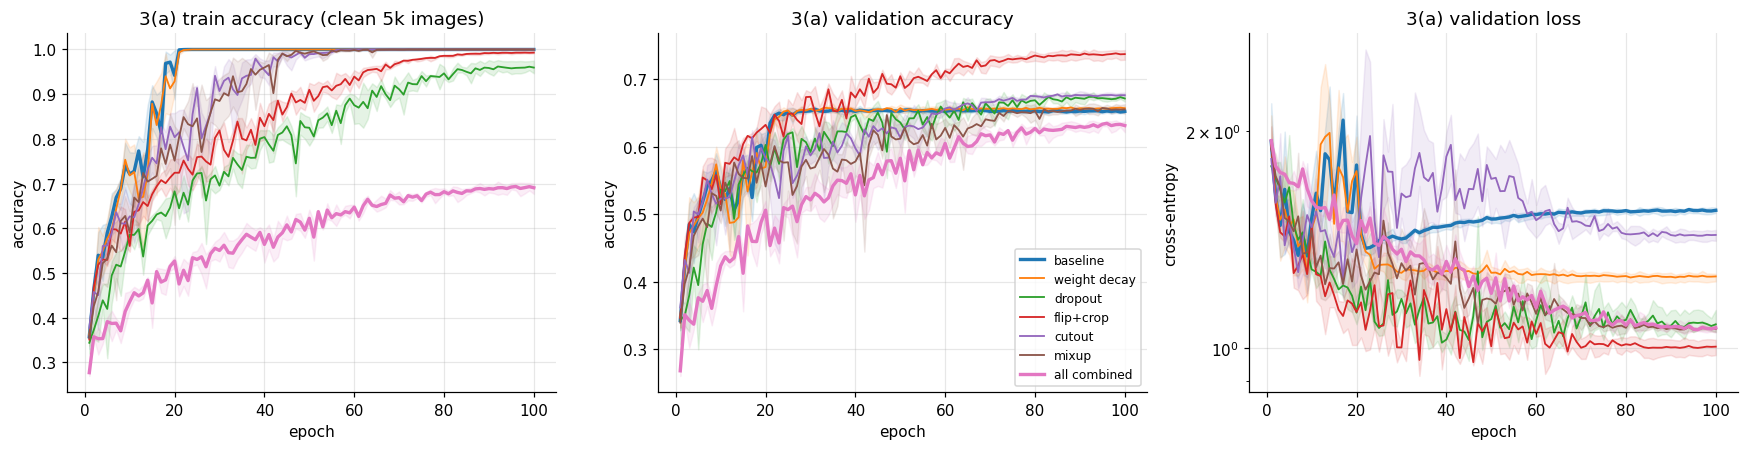

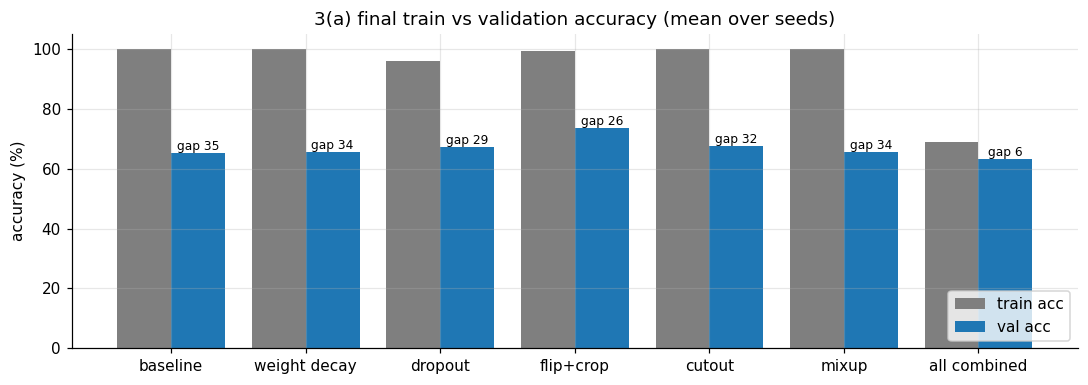

In [18]:
def agg(name, key):
    return np.array([t3a[(name, s)][key] for s in T3A_SEEDS])     # (seeds, epochs)

rows = []
for name in T3A_CONFIGS:
    tr, va = agg(name, 'clean_train_acc')[:, -1] * 100, agg(name, 'val_acc')[:, -1] * 100
    gap = tr - va
    rows.append({'config': name,
                 'train acc (%)': f'{tr.mean():.1f} ± {tr.std():.1f}',
                 'val acc (%)': f'{va.mean():.1f} ± {va.std():.1f}',
                 'gap (pp)': f'{gap.mean():.1f} ± {gap.std():.1f}',
                 'best-epoch val acc (%)': f'{(agg(name, "val_acc").max(1) * 100).mean():.1f}',
                 '_val': va.mean(), '_gap': gap.mean(), '_train': tr.mean()})
t3a_table = pd.DataFrame(rows).set_index('config')
display(t3a_table.drop(columns=['_val', '_gap', '_train']))

cmap = plt.get_cmap('tab10')
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for i, name in enumerate(T3A_CONFIGS):
    lw = 2.2 if name in ('baseline', 'all combined') else 1.2
    for a, key in zip(ax, ('clean_train_acc', 'val_acc', 'val_loss')):
        arr = agg(name, key)
        e = np.arange(1, arr.shape[1] + 1)
        a.plot(e, arr.mean(0), color=cmap(i), lw=lw, label=name)
        if len(T3A_SEEDS) > 1:
            a.fill_between(e, arr.min(0), arr.max(0), color=cmap(i), alpha=0.12)
ax[0].set(xlabel='epoch', ylabel='accuracy', title='3(a) train accuracy (clean 5k images)')
ax[1].set(xlabel='epoch', ylabel='accuracy', title='3(a) validation accuracy')
ax[2].set(xlabel='epoch', ylabel='cross-entropy', title='3(a) validation loss', yscale='log')
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.6))
pos = np.arange(len(T3A_CONFIGS))
ax.bar(pos - 0.2, t3a_table['_train'], 0.4, label='train acc', color='tab:gray')
ax.bar(pos + 0.2, t3a_table['_val'], 0.4, label='val acc', color='tab:blue')
for p, g, v in zip(pos, t3a_table['_gap'], t3a_table['_val']):
    ax.text(p + 0.2, v + 1, f'gap {g:.0f}', ha='center', fontsize=8)
ax.set_xticks(pos); ax.set_xticklabels(T3A_CONFIGS.keys())
ax.set(ylabel='accuracy (%)', ylim=(0, 105), title='3(a) final train vs validation accuracy (mean over seeds)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Supplementary experiment: is "all combined" over-regularised?** In the table above, *all combined* has by far the smallest gap but also the *lowest* validation accuracy, and its clean training accuracy is only about 69%. This suggests the combination is too strong for a 141k-parameter network trained for 100 epochs (underfitting), rather than the regularisers working against each other. Two extra configurations (3 seeds each) test this explanation:
* **all combined, 300 epochs**: the same five regularisers with 3× the training budget, testing whether the combination is limited by training time;
* **flip+crop + cutout + wd**: a lighter combination without the two strongest capacity reducers (mixup, which also softens the labels, and dropout).

all combined, 300 ep. (seed 0) | ep 300/300 | train loss 1.5099 | val loss 0.7885 | val acc 0.7358 | clean train acc 0.8614
all combined, 300 ep. (seed 1) | ep 300/300 | train loss 1.4792 | val loss 0.7606 | val acc 0.7496 | clean train acc 0.8648
all combined, 300 ep. (seed 2) | ep 300/300 | train loss 1.4063 | val loss 0.7709 | val acc 0.7448 | clean train acc 0.8624
flip+crop + cutout + wd (seed 0) | ep 100/100 | train loss 0.3977 | val loss 0.8385 | val acc 0.7400 | clean train acc 0.9512
flip+crop + cutout + wd (seed 1) | ep 100/100 | train loss 0.4062 | val loss 0.8226 | val acc 0.7482 | clean train acc 0.9524
flip+crop + cutout + wd (seed 2) | ep 100/100 | train loss 0.4045 | val loss 0.8524 | val acc 0.7454 | clean train acc 0.9510


,epochs,train acc (%),val acc (%),gap (pp)
config,,,,
baseline,100,100.0 ± 0.0,65.2 ± 0.2,34.8 ± 0.2
flip+crop,100,99.3 ± 0.1,73.7 ± 0.6,25.6 ± 0.7
all combined,100,69.1 ± 1.0,63.1 ± 0.7,5.9 ± 0.4
"all combined, 300 ep.",300,86.3 ± 0.1,74.3 ± 0.6,11.9 ± 0.4
flip+crop + cutout + wd,100,95.2 ± 0.1,74.5 ± 0.3,20.7 ± 0.3


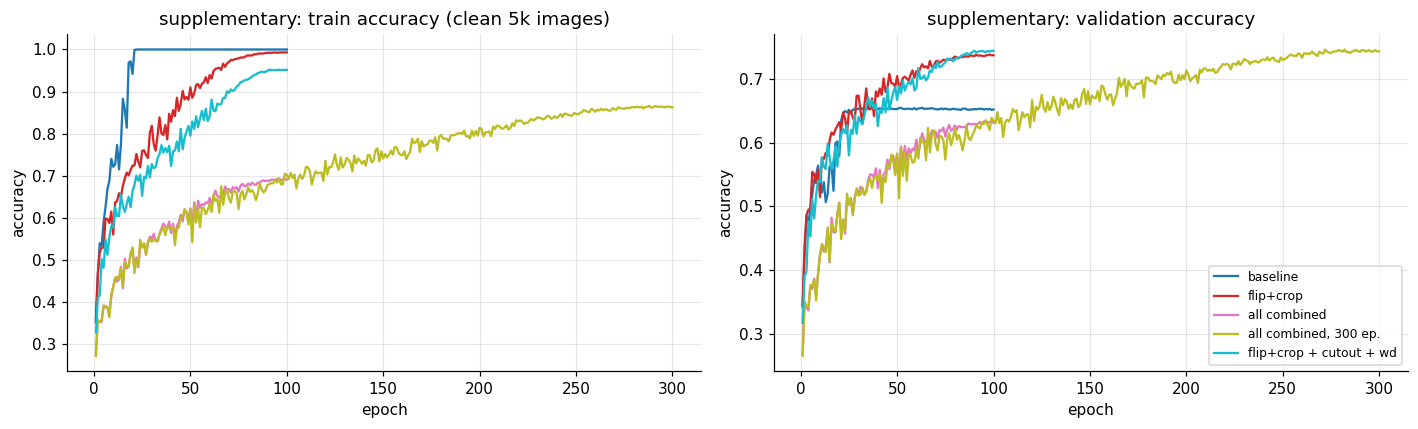

In [19]:
T3A_EXTRA = OrderedDict([
    ('all combined, 300 ep.',   dict(weight_decay=5e-4, dropout=0.3, flip_crop=True, cutout=16, mixup=1.0, epochs=300)),
    ('flip+crop + cutout + wd', dict(weight_decay=5e-4, flip_crop=True, cutout=16)),
])
for name, cfg in T3A_EXTRA.items():
    for seed in T3A_SEEDS:
        run_id = 't3a_extra_' + ''.join(ch if ch.isalnum() else '_' for ch in name) + f'_s{seed}'
        t3a[(name, seed)] = cached(run_id, lambda: run_t3a(cfg, seed, f'{name} (seed {seed})'))

rows = []
for name in ['baseline', 'flip+crop', 'all combined'] + list(T3A_EXTRA):
    tr, va = agg(name, 'clean_train_acc')[:, -1] * 100, agg(name, 'val_acc')[:, -1] * 100
    rows.append({'config': name, 'epochs': len(t3a[(name, T3A_SEEDS[0])]['val_acc']),
                 'train acc (%)': f'{tr.mean():.1f} ± {tr.std():.1f}', 'val acc (%)': f'{va.mean():.1f} ± {va.std():.1f}',
                 'gap (pp)': f'{(tr - va).mean():.1f} ± {(tr - va).std():.1f}'})
display(pd.DataFrame(rows).set_index('config'))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i, name in enumerate(['baseline', 'flip+crop', 'all combined'] + list(T3A_EXTRA)):
    for a, key in zip(ax, ('clean_train_acc', 'val_acc')):
        arr = agg(name, key)
        a.plot(np.arange(1, arr.shape[1] + 1), arr.mean(0), color=cmap([0, 3, 6, 8, 9][i]), label=name)
ax[0].set(xlabel='epoch', ylabel='accuracy', title='supplementary: train accuracy (clean 5k images)')
ax[1].set(xlabel='epoch', ylabel='accuracy', title='supplementary: validation accuracy')
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation.**
* **Baseline: severe overfitting.** With 5k images and ≈141k parameters the network memorises the training set. Clean training accuracy hits 100% by epoch ~20, while validation accuracy stalls at **65.2%**, a **34.8 pp gap**. From epoch ~22 on, the validation loss *rises* steadily, ending around 1.55: once every training image is fitted, the network only grows more confident, including on the validation images it gets wrong.
* **Weight decay** (65.7%, +0.5 pp) has almost no effect on accuracy. The network still reaches 100% training accuracy. With BN, an L2 penalty on conv weights does not limit what the network can represent, because BN undoes any rescaling of the weights; it mainly changes the effective learning rate. It does lower the final validation loss (≈1.25 vs ≈1.55), i.e. it reduces over-confidence.
* **Dropout** (67.1%, +1.9 pp) is the only *model-side* regulariser that stops perfect memorisation (96.0% training accuracy), reducing the gap to 28.8 pp. The random masking stops units from co-adapting to individual training images.
* **Flip+crop** is the **best single regulariser: 73.7% (+8.5 pp)**, with the lowest validation loss (≈1.0). Every epoch shows the network new, label-preserving variants of each image, effectively enlarging the dataset, and it builds in invariances (small translations, mirror symmetry) that hold almost exactly for CIFAR-10.
* **Cutout** (67.6%, +2.4 pp) helps by forcing the network to use several parts of the object, but on its own it still allows 100% training accuracy. A 16×16 hole on an un-shifted image is easy to memorise around.
* **Mixup** (65.5%, +0.3 pp) barely changes accuracy here, and the network still classifies every clean training image correctly. Its effect shows in the **validation loss, which drops from ≈1.55 to ≈1.05**. Training on convex combinations of images *and* labels penalises over-confident predictions, so mixup mainly improves calibration in this setting.
* **All combined: underfitting, not a contradiction.** Stacking all five gives the *smallest gap* (5.9 pp) but the *lowest* validation accuracy (63.1%), because the network cannot even fit the training set (69.1% clean training accuracy, still rising at epoch 100). The supplementary runs confirm this. Training the same combination **3× longer reaches 74.3%**, with training accuracy rising to 86.3%, and a lighter combination (flip+crop + cutout + weight decay) reaches **74.5% in the original 100 epochs**. Both beat every single regulariser, so the regularisers *are* complementary and their benefits add up, but only when the total regularisation strength is matched to the model's capacity and the training budget. This is the bias–variance trade-off: the gap alone is not the goal, since a model can close the gap simply by fitting nothing well.

### 3(b) Plain vs residual networks of depth 6n + 2 (8, 20, 56)

These are the CIFAR networks of He et al. (2016, §4.2): a 3×3 conv with 16 channels, then **three stages of n basic blocks** each with 16 / 32 / 64 channels and feature maps of 32×32 / 16×16 / 8×8, then global average pooling and a 10-way linear layer. Each basic block is conv3×3–BN–ReLU–conv3×3–BN followed by a ReLU. That gives 6n conv layers + 1 stem conv + 1 FC = 6n + 2 layers, with n = 1, 3, 9 for depths 8, 20, 56. All layers use Kaiming initialisation.

**The only difference between the two families is the shortcut.** The residual block outputs $\mathrm{ReLU}(F(x) + x)$; the plain block outputs $\mathrm{ReLU}(F(x))$. Where the shape changes (first block of stages 2 and 3), the paper's **option A** shortcut is used: identity with stride-2 subsampling and zero-padding of the extra channels. It has **no parameters**, so each plain and residual pair has exactly the same parameter count (verified below).

Training follows the paper's recipe, compressed to **40 epochs**: SGD with momentum 0.9, weight decay 1e-4, batch size 128, learning rate 0.1, divided by 10 at 50% and 75% of training, with flip+crop augmentation.

In [20]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.residual = residual
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.reshape = stride != 1 or cin != cout
        self.extra = cout - cin

    def shortcut(self, x):
        """Option A: parameter-free identity; subsample + zero-pad channels when the shape changes."""
        if self.reshape:
            x = x[:, :, ::2, ::2]
            x = F.pad(x, (0, 0, 0, 0, self.extra // 2, self.extra - self.extra // 2))
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class CifarNet(nn.Module):
    """He et al. (2016) CIFAR network of depth 6n+2; residual=False gives the matching plain network."""
    def __init__(self, depth, residual):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        blocks, cin = [], 16
        for stage, cout in enumerate((16, 32, 64)):
            for i in range(n):
                blocks.append(BasicBlock(cin, cout, 2 if (stage > 0 and i == 0) else 1, residual))
                cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, 10)
        kaiming_init(self)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))

for d in (8, 20, 56):
    p, r = n_params(CifarNet(d, False)), n_params(CifarNet(d, True))
    n_conv = sum(isinstance(m, nn.Conv2d) for m in CifarNet(d, True).modules())
    print(f'depth {d:2d}: {n_conv} conv + 1 fc layers | params plain = {p:,} | residual = {r:,} | identical: {p == r}')

depth  8: 7 conv + 1 fc layers | params plain = 75,290 | residual = 75,290 | identical: True
depth 20: 19 conv + 1 fc layers | params plain = 269,722 | residual = 269,722 | identical: True
depth 56: 55 conv + 1 fc layers | params plain = 853,018 | residual = 853,018 | identical: True


In [21]:
T3B_EPOCHS = 40
T3B_DEPTHS = (8, 20, 56)

def run_t3b(depth, residual):
    set_seed(SEED)
    model = CifarNet(depth, residual).to(device)
    epochs, spe = E(T3B_EPOCHS), len(X_train) // 128
    opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[epochs // 2 * spe, epochs * 3 // 4 * spe], gamma=0.1)
    hist = train(model, opt, epochs, sched=sched, augment=make_augment(flip_crop=True),
                 log_every=10, tag=f'{"ResNet" if residual else "Plain"}-{depth}')
    hist['params'] = n_params(model)
    return hist

t3b = OrderedDict()
for residual in (False, True):
    for d in T3B_DEPTHS:
        t3b[(d, residual)] = cached(f't3b_{"res" if residual else "plain"}{d}', lambda: run_t3b(d, residual))

               Plain-8 | ep  10/40 | train loss 0.6392 | val loss 0.7355 | val acc 0.7376
               Plain-8 | ep  20/40 | train loss 0.5196 | val loss 0.8000 | val acc 0.7538
               Plain-8 | ep  30/40 | train loss 0.3850 | val loss 0.4274 | val acc 0.8494
               Plain-8 | ep  40/40 | train loss 0.3651 | val loss 0.4209 | val acc 0.8502
              Plain-20 | ep  10/40 | train loss 0.6032 | val loss 0.6967 | val acc 0.7644
              Plain-20 | ep  20/40 | train loss 0.4471 | val loss 0.6361 | val acc 0.7936
              Plain-20 | ep  30/40 | train loss 0.2522 | val loss 0.3638 | val acc 0.8772
              Plain-20 | ep  40/40 | train loss 0.2247 | val loss 0.3560 | val acc 0.8828
              Plain-56 | ep  10/40 | train loss 1.7278 | val loss 1.7277 | val acc 0.3598
              Plain-56 | ep  20/40 | train loss 1.4784 | val loss 1.5881 | val acc 0.4272
              Plain-56 | ep  30/40 | train loss 1.2713 | val loss 1.2216 | val acc 0.5526
          

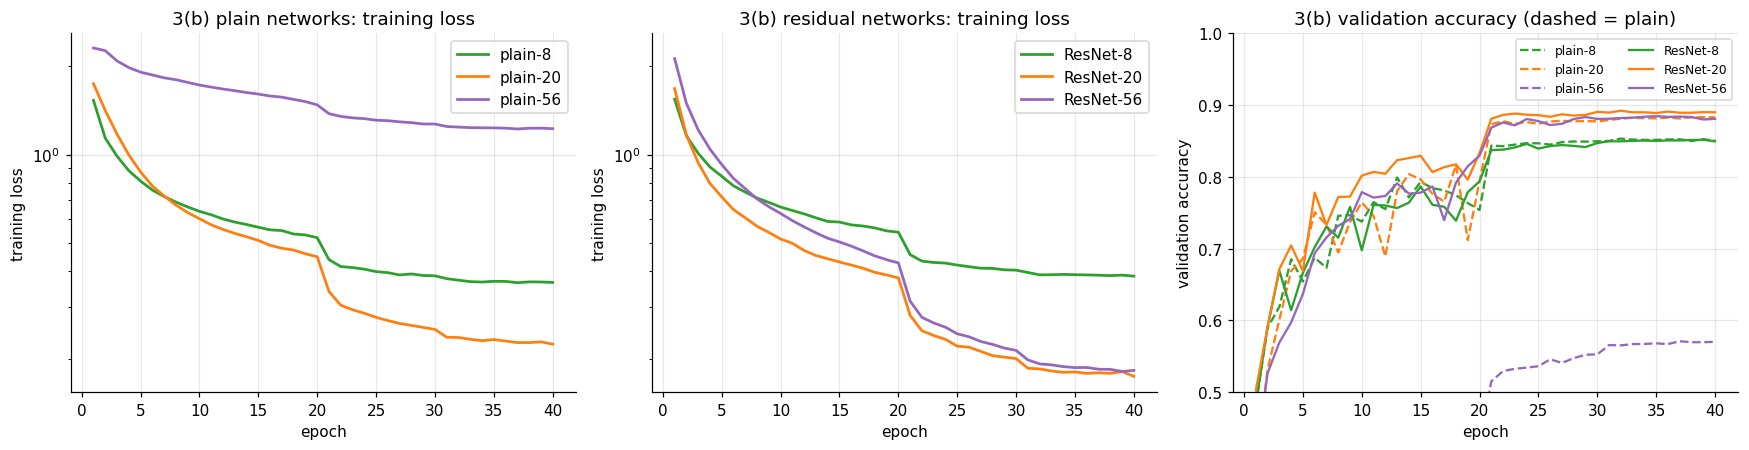

,network,params,final train loss,final train acc (augmented),final val acc,time (min)
0,plain-8,75290,0.3651,0.8730,0.8502,1.6273
1,plain-20,269722,0.2247,0.9207,0.8828,3.6221
2,plain-56,853018,1.2254,0.5559,0.5702,9.4115
3,ResNet-8,75290,0.3838,0.8679,0.8494,1.6308
4,ResNet-20,269722,0.1744,0.9397,0.8898,3.6394
5,ResNet-56,853018,0.1828,0.9359,0.8806,9.5704


In [22]:
depth_col = {8: 'tab:green', 20: 'tab:orange', 56: 'tab:purple'}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for residual, a in ((False, ax[0]), (True, ax[1])):
    for d in T3B_DEPTHS:
        h = t3b[(d, residual)]
        a.plot(np.arange(1, len(h['train_loss']) + 1), h['train_loss'], color=depth_col[d], lw=1.8,
               label=f'{"ResNet" if residual else "plain"}-{d}')
    a.set(xlabel='epoch', ylabel='training loss', yscale='log',
          title=f'3(b) {"residual" if residual else "plain"} networks: training loss')
    a.legend()
ylim = (min(ax[0].get_ylim()[0], ax[1].get_ylim()[0]), max(ax[0].get_ylim()[1], ax[1].get_ylim()[1]))
ax[0].set_ylim(ylim); ax[1].set_ylim(ylim)
for (d, residual), h in t3b.items():
    ax[2].plot(np.arange(1, len(h['val_acc']) + 1), h['val_acc'], '-' if residual else '--', color=depth_col[d],
               label=f'{"ResNet" if residual else "plain"}-{d}')
ax[2].set(xlabel='epoch', ylabel='validation accuracy', title='3(b) validation accuracy (dashed = plain)', ylim=(0.5, 1))
ax[2].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

display(pd.DataFrame([{'network': f'{"ResNet" if r else "plain"}-{d}', 'params': h['params'],
                       'final train loss': h['train_loss'][-1], 'final train acc (augmented)': h['train_acc'][-1],
                       'final val acc': h['val_acc'][-1], 'time (min)': h['wall_time_s'] / 60}
                      for (d, r), h in t3b.items()]).round(4))

To see *why* the plain networks behave as they do, the per-layer gradient norms at initialisation are measured for the 20- and 56-layer networks, as in Task 1(d): one batch of 256 images, BN in training mode, $\|\partial L/\partial W\|$ for every conv layer.

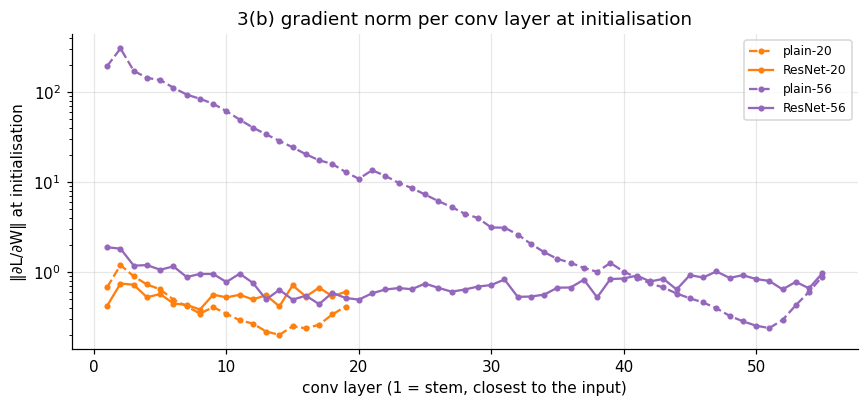

In [23]:
def conv_grad_norms(model, n=256):
    model.train()
    model.zero_grad()
    F.cross_entropy(model(X_train[:n]), y_train[:n]).backward()
    return [m.weight.grad.norm().item() for m in model.modules() if isinstance(m, nn.Conv2d)]

plt.figure(figsize=(8, 3.8))
for d in (20, 56):
    for residual in (False, True):
        set_seed(SEED)
        gn = conv_grad_norms(CifarNet(d, residual).to(device))
        plt.semilogy(np.arange(1, len(gn) + 1), gn, '-' if residual else '--', color=depth_col[d], marker='.',
                     label=f'{"ResNet" if residual else "plain"}-{d}')
plt.xlabel('conv layer (1 = stem, closest to the input)'); plt.ylabel('‖∂L/∂W‖ at initialisation')
plt.title('3(b) gradient norm per conv layer at initialisation')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation.**
* **Plain networks get *worse* with depth beyond 20 layers.** Going from 8 to 20 layers still helps: final training loss falls from 0.365 to 0.225 and validation accuracy rises from 85.0% to 88.3%. But **plain-56 is dramatically worse**. Its training loss is **1.23**, about 5.4× that of plain-20, and it is higher at *every* epoch; it reaches only 55.6% training and 57.0% validation accuracy. This is the **degradation problem** of He et al. It is *not* overfitting, because the failure is in the **training** loss, the very objective being minimised. It is also not a lack of capacity: plain-56 could represent plain-20 exactly by turning its 36 extra layers into identity mappings. The optimizer simply cannot find such a solution.
* **Why: badly scaled gradients.** The gradient plot (measured at initialisation) shows what goes wrong in plain-56. The gradient norms **grow steadily towards the input**, from ≈1 at the last layers to ≈200 at the stem, more than two orders of magnitude. This is not vanishing as in Task 1d but its opposite: deep stacks of conv–BN–ReLU without shortcuts are known to have **exploding gradients at initialisation**, caused by batch norm (Yang et al., 2019; Balduzzi et al., 2017 call the related effect "shattered gradients"). With one global learning rate, the early layers then take steps that are far too large while the late layers take steps that are far too small, so training is unstable and slow. Plain-20 shows a milder version of the same effect (a range of about 0.2–1.2).
* **Residual networks do not degrade.** With a shortcut, each block computes $x + F(x)$. The Jacobian $I + \partial F/\partial x$ gives the gradient a direct path to every layer, and the identity is the default rather than something that has to be learned. The gradients of ResNet-56 stay within ≈0.5–2 across all 55 conv layers. As a result, going from 20 to 56 layers costs nothing: **ResNet-56 (0.183) trains as well as ResNet-20 (0.174)**, and their curves are almost on top of each other after the first learning-rate drop. Both are far below ResNet-8 (0.384). For plain networks the same step in depth multiplies the training loss by 5.4. Plain-56 and ResNet-56 have *identical* parameters and architecture apart from the parameter-free shortcut, yet their validation accuracies are 57.0% and 88.1%.
* **Depth alone does not yet pay off in 40 epochs.** ResNet-56 starts a little slower than ResNet-20 (higher loss in epochs 3–20) and ends level with it, at 88.1% vs 89.0% validation accuracy. A 56-layer network needs a longer schedule to exploit its extra depth: He et al. train for about 164 epochs, where ResNet-56 reaches 93.0% vs 91.3% for ResNet-20. The point demonstrated here is that shortcuts remove the *degradation*: the deeper residual network is not worse, while the deeper plain network fails.
* At depth 8 the two families are indistinguishable (85.0% / 84.9%, losses 0.365 / 0.384), because a 3-block network is easy to optimise either way. The benefit of shortcuts grows with depth, which is exactly the point of residual learning. The learning-rate drops at epochs 20 and 30 cause the sharp falls in loss and jumps in accuracy, but the ordering of the curves is fixed long before the first drop.

---
## Task 4: Best CNN with ≤ 500k parameters and ≤ 20 epochs

**Design (`MiniResNet9`).** This is a scaled-down version of the ResNet-9 that Page (2018) used for fast CIFAR-10 training. Wide-and-shallow residual networks converge in few epochs, which suits a hard 20-epoch budget better than a thin, very deep network.

```
conv3x3(3→32)-BN-ReLU                       32×32
ResBlock(32)       [2 × conv-BN-ReLU, + identity]
conv3x3(32→64)-BN-ReLU, max-pool 2          16×16
ResBlock(64)
conv3x3(64→128)-BN-ReLU, max-pool 2         8×8
ResBlock(128)
global average pool → linear(128→10)
```

**Training recipe:** SGD with Nesterov momentum 0.9, **one-cycle** learning-rate schedule (warm-up for 25% of steps, then cosine annealing), weight decay 5e-4, batch size 128, **label smoothing 0.1**, and **flip + crop + cutout (8×8)** augmentation. Optionally, **test-time augmentation** (TTA) averages the predictions for an image and its mirror image.

**Tuning protocol (validation split only).**
1. Sweep the peak learning rate over {0.05, 0.1, 0.2}.
2. With the best learning rate, run an **ablation study** that changes one design choice at a time: shortcut connections, augmentation (none / no cutout / larger cutout), label smoothing, weight decay, and optimizer (AdamW instead of SGD).
3. Re-run the best configuration with two more seeds to measure the run-to-run noise, so that ablation differences can be judged against it.
4. The final model is the run with the highest validation accuracy. TTA is kept only if it improves *validation* accuracy. Only then is the test set loaded and the final model evaluated **once**.

In [24]:
def conv_bn(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class ResBlock(nn.Module):
    def __init__(self, c, shortcut=True):
        super().__init__()
        self.shortcut = shortcut
        self.body = nn.Sequential(conv_bn(c, c), conv_bn(c, c))

    def forward(self, x):
        return x + self.body(x) if self.shortcut else self.body(x)

class MiniResNet9(nn.Module):
    def __init__(self, widths=(32, 64, 128), shortcut=True):
        super().__init__()
        c1, c2, c3 = widths
        self.net = nn.Sequential(
            conv_bn(3, c1), ResBlock(c1, shortcut),
            conv_bn(c1, c2), nn.MaxPool2d(2), ResBlock(c2, shortcut),
            conv_bn(c2, c3), nn.MaxPool2d(2), ResBlock(c3, shortcut),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c3, 10))
        kaiming_init(self)

    def forward(self, x):
        return self.net(x)

T4_MAX_PARAMS, T4_MAX_EPOCHS = 500_000, 20
P4 = n_params(MiniResNet9())
print(f'MiniResNet9 parameters: {P4:,}  (limit {T4_MAX_PARAMS:,})')
assert P4 <= T4_MAX_PARAMS

MiniResNet9 parameters: 482,730  (limit 500,000)


In [25]:
T4_BASE = dict(lr=0.1, epochs=T4_MAX_EPOCHS, batch=128, opt='sgd', wd=5e-4, label_smoothing=0.1,
               flip_crop=True, cutout=8, shortcut=True, seed=SEED)

def run_t4(name, **overrides):
    """Train MiniResNet9 with the base recipe + overrides; caches the history and saves the weights."""
    cfg = {**T4_BASE, **overrides}
    assert cfg['epochs'] <= T4_MAX_EPOCHS
    weights = f't4_{name}.pt'
    def fn():
        set_seed(cfg['seed'])
        model = MiniResNet9(shortcut=cfg['shortcut']).to(device)
        assert n_params(model) <= T4_MAX_PARAMS
        epochs, spe = E(cfg['epochs']), len(X_train) // cfg['batch']
        if cfg['opt'] == 'sgd':
            opt = torch.optim.SGD(model.parameters(), lr=cfg['lr'], momentum=0.9, nesterov=True, weight_decay=cfg['wd'])
        else:
            opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg['lr'], total_steps=epochs * spe, pct_start=0.25)
        hist = train(model, opt, epochs, batch_size=cfg['batch'], sched=sched,
                     augment=make_augment(cfg['flip_crop'], cfg['cutout']),
                     label_smoothing=cfg['label_smoothing'], log_every=5, tag=name)
        torch.save(model.state_dict(), os.path.join(RESULTS_DIR, weights))
        hist['val_acc_tta'] = evaluate(model, X_val, y_val, tta=True)[1]
        hist['cfg'], hist['params'], hist['weights'] = cfg, n_params(model), weights
        return hist
    return cached(f't4_{name}', fn, extra_files=(weights,))

# Step 1: peak learning-rate sweep with the base recipe
t4 = OrderedDict()
for lr in (0.05, 0.1, 0.2):
    t4[f'lr={lr:g}'] = run_t4(f'lr{lr:g}', lr=lr)
sweep = pd.DataFrame([{'peak LR': k, 'val acc': h['val_acc'][-1], 'val acc (TTA)': h['val_acc_tta']} for k, h in t4.items()])
display(sweep.round(4))
best_lr_t4 = float(max(t4, key=lambda k: t4[k]['val_acc'][-1]).split('=')[1])
print('selected peak learning rate:', best_lr_t4)

                lr0.05 | ep   5/20 | train loss 1.1419 | val loss 0.9609 | val acc 0.6670
                lr0.05 | ep  10/20 | train loss 0.9430 | val loss 0.7392 | val acc 0.7508
                lr0.05 | ep  15/20 | train loss 0.8398 | val loss 0.4606 | val acc 0.8530
                lr0.05 | ep  20/20 | train loss 0.7456 | val loss 0.3492 | val acc 0.8986
                 lr0.1 | ep   5/20 | train loss 1.0799 | val loss 0.7907 | val acc 0.7374
                 lr0.1 | ep  10/20 | train loss 0.9217 | val loss 0.7084 | val acc 0.7600
                 lr0.1 | ep  15/20 | train loss 0.8305 | val loss 0.4451 | val acc 0.8612
                 lr0.1 | ep  20/20 | train loss 0.7115 | val loss 0.3090 | val acc 0.9144
                 lr0.2 | ep   5/20 | train loss 1.0547 | val loss 0.9353 | val acc 0.6800
                 lr0.2 | ep  10/20 | train loss 0.9493 | val loss 0.8686 | val acc 0.7040
                 lr0.2 | ep  15/20 | train loss 0.8606 | val loss 0.5511 | val acc 0.8272
          

,peak LR,val acc,val acc (TTA)
0,lr=0.05,0.8986,0.9064
1,lr=0.1,0.9144,0.9200
2,lr=0.2,0.9140,0.9206


selected peak learning rate: 0.1


In [26]:
# Step 2: ablations, each changing ONE design choice of the tuned recipe
ABLATIONS = OrderedDict([   # display name -> (run id, overrides)
    ('no shortcut (plain)',        ('abl_no_shortcut', dict(shortcut=False))),
    ('no augmentation',            ('abl_no_aug',      dict(flip_crop=False, cutout=0))),
    ('flip+crop only (no cutout)', ('abl_no_cutout',   dict(cutout=0))),
    ('cutout 16 instead of 8',     ('abl_cutout16',    dict(cutout=16))),
    ('no label smoothing',         ('abl_no_ls',       dict(label_smoothing=0.0))),
    ('no weight decay',            ('abl_no_wd',       dict(wd=0.0))),
    ('AdamW instead of SGD',       ('abl_adamw',       dict(opt='adamw', lr=3e-3, wd=0.05))),
])
ref_key = f'lr={best_lr_t4:g}'
for name, (run_id, ov) in ABLATIONS.items():
    t4[name] = run_t4(run_id, **{'lr': best_lr_t4, **ov})

# Step 3: seed noise of the reference configuration
seed_accs = [t4[ref_key]['val_acc'][-1]]
for s in (1, 2):
    seed_accs.append(run_t4(f'ref_seed{s}', lr=best_lr_t4, seed=s)['val_acc'][-1])
noise = float(np.std(seed_accs))
print(f'reference recipe, 3 seeds: val acc = {np.mean(seed_accs):.4f} ± {noise:.4f}')

       abl_no_shortcut | ep   5/20 | train loss 1.0707 | val loss 0.7880 | val acc 0.7424
       abl_no_shortcut | ep  10/20 | train loss 0.9247 | val loss 0.7480 | val acc 0.7506
       abl_no_shortcut | ep  15/20 | train loss 0.8316 | val loss 0.4949 | val acc 0.8418
       abl_no_shortcut | ep  20/20 | train loss 0.7113 | val loss 0.3310 | val acc 0.9098
            abl_no_aug | ep   5/20 | train loss 0.9503 | val loss 0.7730 | val acc 0.7524
            abl_no_aug | ep  10/20 | train loss 0.7610 | val loss 0.6368 | val acc 0.8030
            abl_no_aug | ep  15/20 | train loss 0.6156 | val loss 0.5579 | val acc 0.8410
            abl_no_aug | ep  20/20 | train loss 0.5315 | val loss 0.4722 | val acc 0.8816
         abl_no_cutout | ep   5/20 | train loss 1.0305 | val loss 0.8096 | val acc 0.7306
         abl_no_cutout | ep  10/20 | train loss 0.8700 | val loss 0.5799 | val acc 0.8194
         abl_no_cutout | ep  15/20 | train loss 0.7803 | val loss 0.4375 | val acc 0.8666
         a

,configuration,val acc,Δ vs reference (pp),val acc (TTA)
0,reference (tuned recipe),0.9144,0.00,0.9200
1,no shortcut (plain),0.9098,-0.46,0.9192
2,no augmentation,0.8816,-3.28,0.9004
3,flip+crop only (no cutout),0.9152,0.08,0.9206
4,cutout 16 instead of 8,0.9070,-0.74,0.9140
5,no label smoothing,0.9098,-0.46,0.9162
6,no weight decay,0.8962,-1.82,0.9052
7,AdamW instead of SGD,0.9086,-0.58,0.9166


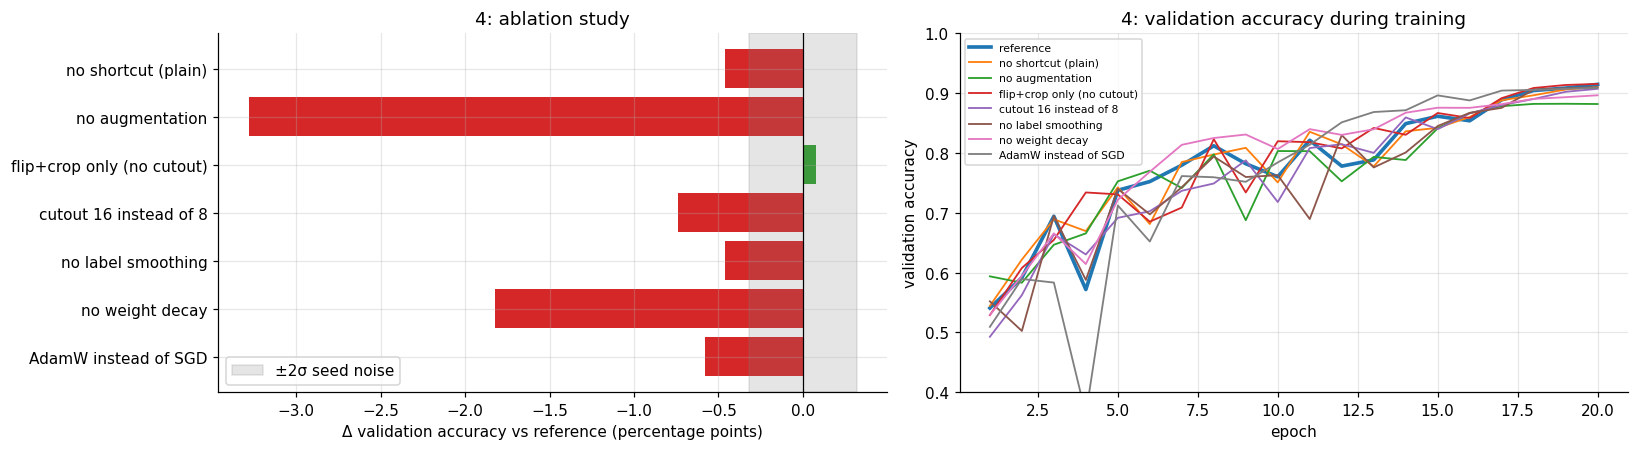

In [27]:
ref_acc = t4[ref_key]['val_acc'][-1]
abl = pd.DataFrame([{'configuration': 'reference (tuned recipe)', 'val acc': ref_acc, 'Δ vs reference (pp)': 0.0,
                     'val acc (TTA)': t4[ref_key]['val_acc_tta']}] +
                   [{'configuration': name, 'val acc': t4[name]['val_acc'][-1],
                     'Δ vs reference (pp)': 100 * (t4[name]['val_acc'][-1] - ref_acc),
                     'val acc (TTA)': t4[name]['val_acc_tta']} for name in ABLATIONS])
display(abl.round(4))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
d = abl.iloc[1:]
cols = ['tab:red' if v < 0 else 'tab:green' for v in d['Δ vs reference (pp)']]
ax[0].barh(d['configuration'], d['Δ vs reference (pp)'], color=cols)
ax[0].axvspan(-200 * noise, 200 * noise, color='grey', alpha=0.2, label='±2σ seed noise')
ax[0].axvline(0, color='k', lw=0.8)
ax[0].set(xlabel='Δ validation accuracy vs reference (percentage points)', title='4: ablation study')
ax[0].legend(loc='lower left'); ax[0].invert_yaxis()
for name in [ref_key] + list(ABLATIONS):
    h = t4[name]
    ax[1].plot(np.arange(1, len(h['val_acc']) + 1), h['val_acc'], lw=2.4 if name == ref_key else 1.2,
               label='reference' if name == ref_key else name)
ax[1].set(xlabel='epoch', ylabel='validation accuracy', title='4: validation accuracy during training', ylim=(0.4, 1))
ax[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

**Interpretation of the ablation.** The learning-rate sweep chose a peak LR of **0.1** (91.44%). The value 0.2 is practically tied (91.40%), while 0.05 is clearly worse (89.86%), so the optimum lies inside the sweep and the result is not sensitive to the exact choice between 0.1 and 0.2. Every ablation keeps η = 0.1 and changes *one* design choice. The seed noise of the reference recipe is **91.27 ± 0.16%** (3 seeds), so the grey band (±2σ ≈ ±0.3 pp) marks differences that are not significant.
* **Augmentation** is by far the most important factor: **−3.3 pp** without it (88.2%). Its final training loss is 0.53, essentially the minimum possible with label smoothing 0.1 (the entropy of the smoothed targets, ≈0.50), so the un-augmented network has memorised its training set. The augmented runs stay near 0.71 on their harder, randomly transformed batches. Flip+crop provides all of the benefit. Removing cutout changes accuracy by **+0.1 pp** (within noise), and **16×16 cutout is clearly worse (−0.7 pp)**. In a 20-epoch budget, occluding patches add little beyond flip+crop, and a large patch is too strong a regulariser.
* **Weight decay is the second most important choice: −1.8 pp** without it. Interestingly, the run without weight decay is *ahead* in the middle of training (80.6% vs 76.0% at epoch 10) but ends lower. With BN, weight decay keeps the weights small and therefore the *effective* learning rate high, which keeps training noisy until the annealing phase and then lands in a flatter, better-generalising solution.
* **AdamW (−0.6 pp)**, **no label smoothing (−0.5 pp)** and **no shortcuts (−0.5 pp)** are smaller effects, just outside the noise band. SGD with Nesterov momentum generalising slightly better than Adam(W) for CNNs on CIFAR is a common finding. Adam's advantage in Task 2c came from a network *without* BN and a constant learning rate; with BN and a one-cycle schedule, SGD's step-size sensitivity is largely solved. Label smoothing prevents over-confident logits. Shortcuts matter less here than in Task 3b because this network has only three residual blocks and gets its accuracy from width, not depth. They cost no parameters, so keeping them is free.
* **Test-time augmentation** (averaging the predictions for an image and its mirror image) adds **+0.5 to +1.9 pp** in *every* configuration (+0.6 pp for the reference), at no training cost. The gain is largest for the un-augmented model (+1.9 pp), which never saw mirrored images during training.

The validation curves show the effect of the one-cycle schedule: noisy, slowly rising accuracy during the high-learning-rate phase, then a steep climb in the last ~6 epochs as the learning rate is annealed.

### Final model: selected on validation, evaluated on the test set **once**

In [28]:
# select the final model purely on validation accuracy
final_key = max(t4, key=lambda k: t4[k]['val_acc'][-1])
final = t4[final_key]
use_tta = final['val_acc_tta'] > final['val_acc'][-1]
final_file = os.path.join(RESULTS_DIR, final['weights'])
print(f'final model: "{final_key}" | config: {final["cfg"]}')
print(f'parameters: {final["params"]:,} | epochs: {len(final["val_acc"])} | val acc: {final["val_acc"][-1]:.4f} | '
      f'val acc with flip-TTA: {final["val_acc_tta"]:.4f} -> use TTA: {use_tta}')

final_model = MiniResNet9(shortcut=final['cfg']['shortcut']).to(device)
final_model.load_state_dict(torch.load(final_file, map_location=device))

# ===================== the ONLY use of the CIFAR-10 test set in this notebook =====================
test_data, test_labels = load_cifar10('test')
X_test = normalize(torch.from_numpy(test_data).permute(0, 3, 1, 2).float().div(255)).to(device)
y_test = torch.from_numpy(test_labels).to(device)
test_pred = predict_logprobs(final_model, X_test, tta=use_tta).argmax(1)
test_acc = (test_pred == y_test).float().mean().item()
print(f'\n>>> TEST ACCURACY of the final model: {test_acc * 100:.2f}%  ({len(y_test):,} images, evaluated once)')

final model: "flip+crop only (no cutout)" | config: {'lr': 0.1, 'epochs': 20, 'batch': 128, 'opt': 'sgd', 'wd': 0.0005, 'label_smoothing': 0.1, 'flip_crop': True, 'cutout': 0, 'shortcut': True, 'seed': 42}
parameters: 482,730 | epochs: 20 | val acc: 0.9152 | val acc with flip-TTA: 0.9206 -> use TTA: True


100%|██████████| 22.8M/22.8M [00:00<00:00, 57.3MB/s]



>>> TEST ACCURACY of the final model: 91.42%  (10,000 images, evaluated once)


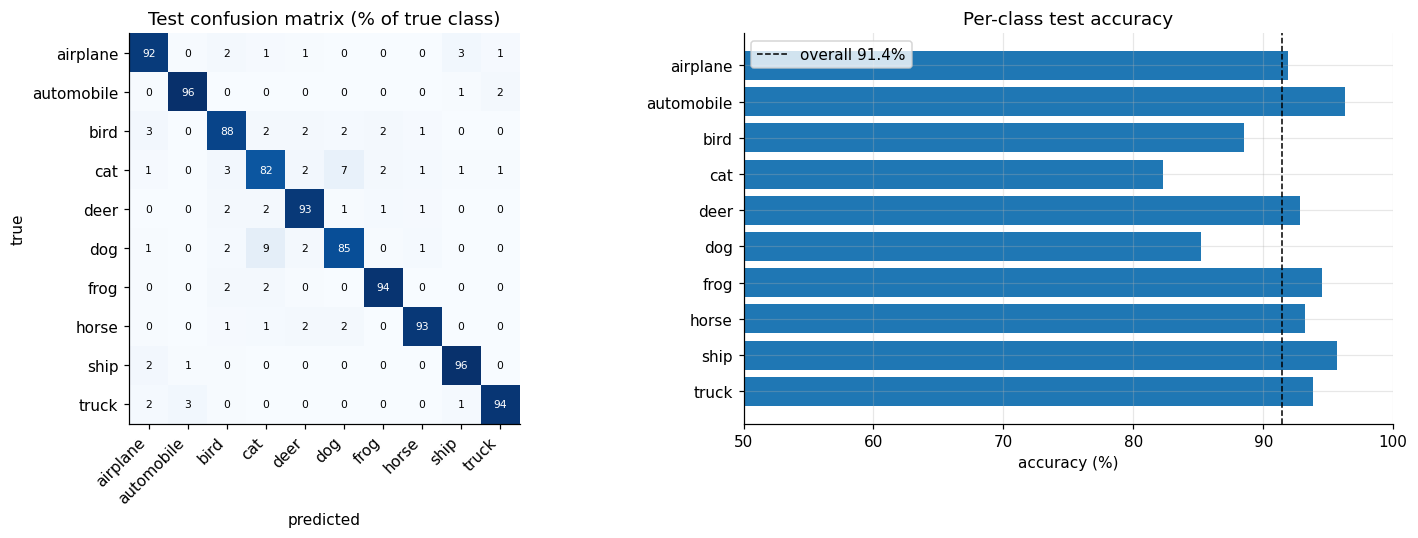

In [29]:
cm = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(y_test.cpu(), test_pred.cpu()):
    cm[t, p] += 1
cmn = (cm / cm.sum(1, keepdim=True)).numpy()
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.2, 1]})
im = ax[0].imshow(cmn, cmap='Blues')
for i in range(10):
    for j in range(10):
        ax[0].text(j, i, f'{cmn[i, j] * 100:.0f}', ha='center', va='center', fontsize=7,
                   color='white' if cmn[i, j] > 0.5 else 'black')
ax[0].set_xticks(range(10)); ax[0].set_xticklabels(CLASSES, rotation=45, ha='right')
ax[0].set_yticks(range(10)); ax[0].set_yticklabels(CLASSES)
ax[0].set(xlabel='predicted', ylabel='true', title='Test confusion matrix (% of true class)')
ax[0].grid(False)
per_class = np.diag(cmn)
ax[1].barh(CLASSES, per_class * 100, color='tab:blue')
ax[1].axvline(test_acc * 100, color='k', ls='--', lw=1, label=f'overall {test_acc * 100:.1f}%')
ax[1].set(xlabel='accuracy (%)', title='Per-class test accuracy', xlim=(50, 100))
ax[1].invert_yaxis(); ax[1].legend()
plt.tight_layout()
plt.show()

**Interpretation.** The run with the highest validation accuracy was *flip+crop only* (no cutout): peak LR 0.1, SGD with Nesterov momentum, weight decay 5e-4, label smoothing 0.1, 482,730 parameters, 20 epochs, plus flip test-time augmentation. It was chosen using the validation split only, by the protocol fixed in advance (highest validation accuracy wins). Its lead over the reference recipe (+0.1 pp) is within seed noise, so the two are effectively equivalent; the simpler recipe without cutout is a perfectly good final choice.

The final model reaches **91.42% test accuracy**, about 0.6 pp below its validation accuracy with TTA (92.06%). A small gap is expected for two reasons:
1. **Selection bias.** The learning rate, the final configuration and the TTA decision were all chosen to *maximise* accuracy on the same 5k validation images, so the winning validation score is optimistically biased.
2. **Sampling noise.** An accuracy near 92% measured on 5k images has a standard error of about $\sqrt{0.92\cdot0.08/5000}\approx0.4$ pp, and 0.3 pp on the 10k test images.

This is exactly why the test set was kept untouched until the end. The 91.42% is an unbiased estimate of how the model performs on new data, while the 92.06% validation figure is not.

The confusion matrix shows the familiar CIFAR-10 pattern. Vehicles are recognised best (automobile and ship 96%, truck 94%, airplane 92%), along with frog (94%), deer and horse (93%). The errors are concentrated in the visually similar animal classes: **cat (82%)**, **dog (85%)** and bird (88%) are the weakest, and the two largest off-diagonal entries are **dog → cat (9%)** and **cat → dog (7%)**. These classes share textures, colours and poses at 32×32 resolution, and that is where a larger model or a longer schedule would help most. The most frequent vehicle errors are truck → automobile and airplane → ship (3% each); the latter is plausibly caused by the shared blue sky / water background.

---
## 5. Summary

In [30]:
lines = [
    ('1(c)', 'MLP (manual backprop, SGD) – final val acc', f"{h1c['val_acc'][-1] * 100:.2f}%"),
    ('2(c)', 'best val acc: SGD / SGD+mom / Adam',
     ' / '.join(f"{best_val[(o, best_lr[o])] * 100:.1f}% (η={best_lr[o]:g})" for o in T2C_GRID)),
    ('3(a)', 'val acc (5k train): baseline / flip+crop / all combined (100 ep.) / all combined (300 ep.)',
     f"{t3a_table.loc['baseline', '_val']:.1f}% / {t3a_table.loc['flip+crop', '_val']:.1f}% / "
     f"{t3a_table.loc['all combined', '_val']:.1f}% / {agg('all combined, 300 ep.', 'val_acc')[:, -1].mean() * 100:.1f}%"),
    ('3(b)', 'final train loss: plain-20 / plain-56 / ResNet-56',
     f"{t3b[(20, False)]['train_loss'][-1]:.3f} / {t3b[(56, False)]['train_loss'][-1]:.3f} / {t3b[(56, True)]['train_loss'][-1]:.3f}"),
    ('3(b)', 'val acc plain-56 vs ResNet-56',
     f"{t3b[(56, False)]['val_acc'][-1] * 100:.2f}% vs {t3b[(56, True)]['val_acc'][-1] * 100:.2f}%"),
    ('4', f'final model ({final["params"]:,} params, 20 epochs) – val / val with TTA / TEST acc',
     f"{final['val_acc'][-1] * 100:.2f}% / {final['val_acc_tta'] * 100:.2f}% / {test_acc * 100:.2f}%"),
]
display(pd.DataFrame(lines, columns=['task', 'result', 'value']).set_index('task'))
total_min = sum(h.get('wall_time_s', 0) for coll in (t2c, t3a, t3b, t4) for h in coll.values()) / 60
print(f'total training time of all cached runs: {total_min:.0f} min')

,result,value
task,,
1(c),"MLP (manual backprop, SGD) – final val acc",52.02%
2(c),best val acc: SGD / SGD+mom / Adam,69.0% (η=0.03) / 69.9% (η=0.003) / 76.9% (η=0.001)
3(a),val acc (5k train): baseline / flip+crop / all combined (100 ep.) / all combined (300 ep.),65.2% / 73.7% / 63.1% / 74.3%
3(b),final train loss: plain-20 / plain-56 / ResNet-56,0.225 / 1.225 / 0.183
3(b),val acc plain-56 vs ResNet-56,57.02% vs 88.06%
4,"final model (482,730 params, 20 epochs) – val / val with TTA / TEST acc",91.52% / 92.06% / 91.42%


total training time of all cached runs: 70 min


**Conclusions.**
* **Backpropagation (Task 1).** The hand-written gradients match autograd to float64 machine precision and match finite differences to $10^{-7}$ or better. Gradient flow at initialisation depends on the activation: through 10 sigmoid layers the gradient shrinks by a factor of about $10^{5}$, while with ReLU + He initialisation it stays constant. Without convolutions, the MLP overfits early and plateaus at about 52%.
* **Optimizers (Task 2).** My SGD-momentum and Adam reproduce `torch.optim` exactly. On an ill-conditioned quadratic, momentum averages gradients over time and Adam rescales each coordinate, and both beat SGD by 30–70× in loss after 100 steps. On a CNN without BN, Adam is the most accurate (76.9%) and the fastest to train, but every optimizer fails one decade above its best learning rate: SGD and SGD + momentum diverge, and Adam collapses to a constant output. Momentum acts like a 10× larger SGD step, and the best learning rate differs by 30× between SGD and Adam.
* **Regularization (Task 3a).** With 5k images every model can memorise the data. Data augmentation (flip+crop, +8.5 pp) is the most effective single regulariser, ahead of cutout (+2.4) and dropout (+1.9), while weight decay and mixup alone barely change accuracy, although they reduce over-confidence. Stacking all of them over-regularises the small network in 100 epochs (63.1%). With 3× more epochs the same combination reaches 74.3%, and a lighter combination reaches 74.5%. The regularisers are complementary, but their total strength has to match the model capacity and the training time.
* **Residual connections (Task 3b).** Plain networks degrade with depth: plain-56 has a training loss of 1.23 against 0.23 for plain-20, with exploding, badly scaled gradients. Identical networks with parameter-free shortcuts do not degrade: ResNet-56 trains as well as ResNet-20 (0.18 vs 0.17) and reaches 88.1% validation accuracy vs 57.0% for plain-56.
* **Best CNN (Task 4).** A 482,730-parameter residual network trained for 20 epochs with a one-cycle schedule, SGD with Nesterov momentum, weight decay, label smoothing, flip+crop augmentation and flip TTA reaches **91.42% test accuracy**. The protocol tuned on validation only and evaluated the test set once. Augmentation (−3.3 pp without) and weight decay (−1.8 pp without) were the most important design choices in the ablation.